# m6A switch-competence and CLIP enrichment -- four 3'UTR regions compared

**Visualization only.** Every number is produced by scripts and read from `ROOT`.
To regenerate everything:
```
bash pipeline/datasets/MN_diff/run_all.sh --only m6a_regions          # one run per region (folding, stats, CLIP; no CLIP for region 0)
bash pipeline/datasets/MN_diff/run_all.sh --only m6a_regions_compare  # -> ROOT/comparison/*.csv (cross-region tables and tests)
```

| region | window | candidate RBPs (CLIP tests) | results |
|---|---|---|---|
| region 0 | `[-100:+100]` around the **3'UTR start** (stop codon) | -- (no CLIP test) | `ROOT/utr_start_m100_100/` |
| region 1 | `[-350:0]` upstream of the **proximal** PAS | `../Tables/Figure_regulators_lengthening/regulators_of_nuclear_3UTR_lengthening_D22_to_D35_CTRL_region1_upstream_pPAS_APA_vs_nuclear_retention_class.csv` | `ROOT/proximal_m350_0/` |
| region 2 | `[0:200]` downstream of the **proximal** PAS | `../Tables/Figure_regulators_lengthening/regulators_of_nuclear_3UTR_lengthening_D22_to_D35_CTRL_region2_downstream_pPAS_APA_vs_nuclear_retention_class.csv` | `ROOT/proximal_0_200/` |
| region 3 | `[-350:0]` upstream of the **distal** PAS | `../Tables/Figure_regulators_lengthening/regulators_of_nuclear_3UTR_lengthening_D22_to_D35_CTRL_region3_upstream_dPAS_APA_vs_nuclear_retention_class.csv` | `ROOT/distal_m350_0/` |

Each region folder holds `switch_competence_u_tract/`, `switch_competence_gu_motif/` (per-site,
per-transcript, `group_stats.csv`), `clip_u_tract_enrichment/`, `clip_gu_motif_enrichment/`
(`clip_enrichment.csv`), each with a `params.json` provenance file.

**Region 0** is anchored on the 3'UTR start (first nt after the stop codon; the same for the proximal and distal isoform
of every pair, folded on the proximal one): 100 nt of CDS including the stop codon + the first 100 nt of the 3'UTR,
genomic sequence. When the exon holding the stop codon starts less than 100 nt upstream (2,060 / 7,877 transcripts,
exon structure from GENCODE v44), the window starts at that exon's first nt instead, so no intron is folded
(window 103-200 nt).

**Definitions** (identical in all regions). A measured (RMBase) m6A site at `i` in the window is
switch-competent if its most probable ViennaRNA partner `j` has `p(i,j) >= 0.5` and
- **UUUs**: `j` is part of a run of >= 3 consecutive U's
- **UG motifs**: `j` overlaps a `UGU`/`UUG`/`GUG`/`GUU` 3-mer.

**Groups**: nuclear-lengthened pairs (`pairs_distals_D22_Nuclear_Wildtype_vs_D35_Nuclear_Wildtype.csv`)
vs. all other pairs. **CLIP**: for each candidate RBP, the fraction of its crosslinks in a given element
type (U-tracts or UG 3-mers) of the window that fall in a switch-linked element, vs. that element
type's switch-linked share (one-sided binomial test).

In [1]:
import json
import os

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

matplotlib.rcParams["pdf.fonttype"] = 42
matplotlib.rcParams["ps.fonttype"] = 42

from utrals.paths import PROJECT_DIR  # data locations outside the repository (paths.env)
ROOT = f"{PROJECT_DIR}/MN_diff/results/RNA_modifs/m6A/regions"
CMP = f"{ROOT}/comparison"

figures_subfolder = "../Figures/Figure_m6A/m6A_switch_competence_3UTR_regions"
os.makedirs(figures_subfolder, exist_ok=True)

# save_figure saves a figure and lists it, with its legend, in ../Figures/README.md
from functools import partial
from utrals import figures
save_figure = partial(figures.save_figure, notebook="Figure_m6A_switch_regions_summary.ipynb")
figures.fix_random_seeds(0)  # fixed jitter and bootstrap confidence intervals: identical figures on every run

group_order = ["Other", "Nuclear-lengthened"]
group_palette = {"Other": "#aaaaaa", "Nuclear-lengthened": "green"}
definitions = ["UUUs", "UG motifs"]
def_palette = {"UUUs": "#4c72b0", "UG motifs": "#dd8452"}


def stars(p):
    return "***" if p < 1e-4 else "**" if p < 1e-2 else "*" if p < 0.05 else "ns"

## Regions, inputs and provenance

In [2]:
regions = pd.read_csv(f"{CMP}/regions.csv")
region_order = regions["region"].tolist()
# regions with a CLIP test (region 0 has no candidate list)
clip_region_order = [r for r in region_order if r in set(pd.read_csv(f"{CMP}/clip_enrichment_all_regions.csv")["region"])]
with open(f"{CMP}/params.json") as f:
    p = json.load(f)
print(f"comparison produced {p['timestamp']}, git {p['git_commit'][:8]} (scripts dirty: {p['git_scripts_dirty']})")
# candidate RBP list of each region: file name only (full path in regions.csv)
regions.assign(candidates=regions["candidates"].map(lambda f: os.path.basename(f) if isinstance(f, str) else f))

comparison produced 2026-10-13T11:48:33, git e404cc42 (scripts dirty: True)


,region,subdir,isoform,anchor,wl,wr,n_windows_cut_at_exon_start,candidates
0,3'UTR start [-100:+100],utr_start_m100_100,proximal,utr_start,-100,100,2060,NaN
1,proximal [-350:0],proximal_m350_0,proximal,pas,-350,0,0,candidates_lengthening_in_CTRL_region1.csv
2,proximal [0:200],proximal_0_200,proximal,pas,0,200,0,candidates_lengthening_in_CTRL_region2.csv
3,distal [-350:0],distal_m350_0,distal,pas,-350,0,0,candidates_lengthening_in_CTRL_region3.csv


In [3]:
overview = pd.read_csv(f"{CMP}/overview.csv")
overview[overview["group"] == "all"].drop(columns="group")

,region,definition,n_transcripts,n_transcripts_with_m6a,n_m6a_sites,n_A,n_switch_competent,frac_switch_per_m6a_site,switch_per_1000_A,mean_switch_per_transcript
0,3'UTR start [-100:+100],UUUs,7877,7030,29431,402877,1439,0.048894,3.571810,0.182684
3,3'UTR start [-100:+100],UG motifs,7877,7030,29431,402877,4729,0.160681,11.738074,0.600355
6,proximal [-350:0],UUUs,7877,7070,44336,745164,2993,0.067507,4.016565,0.379967
9,proximal [-350:0],UG motifs,7877,7070,44336,745164,8827,0.199093,11.845715,1.120604
12,proximal [0:200],UUUs,7877,5601,19933,427121,1475,0.073998,3.453354,0.187254
15,proximal [0:200],UG motifs,7877,5601,19933,427121,4435,0.222495,10.383474,0.563032
18,distal [-350:0],UUUs,7877,4765,22313,792463,1754,0.078609,2.213353,0.222674
21,distal [-350:0],UG motifs,7877,4765,22313,792463,5557,0.249048,7.012315,0.705472


## 1. How common are switch-competent m6A sites in each region? (all transcripts)

Pooled over all transcripts of the region. The windows have different lengths (350 vs. 200 nt; region 0 is <= 200 nt),
so the comparison uses rates: per measured m6A site, and per A nucleotide of the window.
Pairwise Fisher tests between regions, BH-corrected (`between_region_tests.csv`).

In [4]:
between = pd.read_csv(f"{CMP}/between_region_tests.csv")
between

,definition,metric,comparison,test,rate_a,rate_b,odds_ratio,statistic,p_value,q_value_bh
0,UUUs,per_m6a_site,all regions,chi-square (dof=3),NaN,NaN,NaN,219.456130,2.632004e-47,2.632004e-47
1,UUUs,per_m6a_site,3'UTR start [-100:+100] vs proximal [-350:0],Fisher exact (two-sided),0.048894,0.067507,0.710104,NaN,6.662445e-26,1.332489e-25
2,UUUs,per_m6a_site,3'UTR start [-100:+100] vs proximal [0:200],Fisher exact (two-sided),0.048894,0.073998,0.643309,NaN,1.301147e-30,3.903441e-30
3,UUUs,per_m6a_site,3'UTR start [-100:+100] vs distal [-350:0],Fisher exact (two-sided),0.048894,0.078609,0.602559,NaN,1.888884e-43,1.133331e-42
4,UUUs,per_m6a_site,proximal [-350:0] vs proximal [0:200],Fisher exact (two-sided),0.067507,0.073998,0.905936,NaN,2.999191e-03,3.599029e-03
5,UUUs,per_m6a_site,proximal [-350:0] vs distal [-350:0],Fisher exact (two-sided),0.067507,0.078609,0.848549,NaN,1.790924e-07,2.686386e-07
6,UUUs,per_m6a_site,proximal [0:200] vs distal [-350:0],Fisher exact (two-sided),0.073998,0.078609,0.936655,NaN,7.525420e-02,7.525420e-02
7,UUUs,per_A,all regions,chi-square (dof=3),NaN,NaN,NaN,418.071229,2.695171e-90,3.593561e-90
8,UUUs,per_A,3'UTR start [-100:+100] vs proximal [-350:0],Fisher exact (two-sided),0.003572,0.004017,0.888873,NaN,2.381755e-04,2.858107e-04
9,UUUs,per_A,3'UTR start [-100:+100] vs proximal [0:200],Fisher exact (two-sided),0.003572,0.003453,1.034425,NaN,3.630421e-01,3.630421e-01


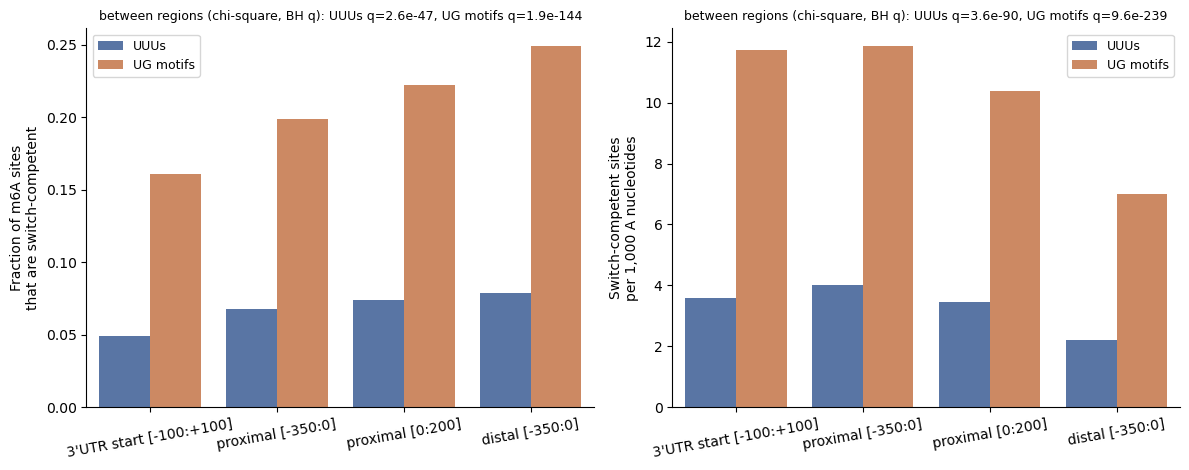

In [5]:
allg = overview[overview["group"] == "all"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, (col, metric, ylabel) in zip(axes, [
        ("frac_switch_per_m6a_site", "per_m6a_site", "Fraction of m6A sites\nthat are switch-competent"),
        ("switch_per_1000_A", "per_A", "Switch-competent sites\nper 1,000 A nucleotides")]):
    sns.barplot(data=allg, x="region", y=col, hue="definition", order=region_order,
                hue_order=definitions, palette=def_palette, ax=ax)
    chi = between[(between["metric"] == metric) & (between["comparison"] == "all regions")]
    ax.set_title("between regions (chi-square, BH q): " + ", ".join(
        f"{r.definition} q={r.q_value_bh:.1e}" for r in chi.itertuples()), fontsize=9)
    ax.set_xlabel("")
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", labelrotation=10)
    ax.legend(title="", fontsize=9)
    sns.despine(ax=ax)
plt.tight_layout()
# plt.savefig(f"{figures_subfolder}/switch_rate_by_region.pdf", bbox_inches="tight")
plt.show()

## 2. Nuclear-lengthened vs. nuclear-shortened vs. other pairs (D22 vs. D35, WT), region by region

Nuclear-lengthened = `pairs_distals_D22_Nuclear_Wildtype_vs_D35_Nuclear_Wildtype.csv` (2,481 pairs),
nuclear-shortened = `pairs_proximals_D22_Nuclear_Wildtype_vs_D35_Nuclear_Wildtype.csv` (210),
other = the rest of the analysed pairs (5,186; the shortened pairs are no longer in "other").
Brackets = BH q-values of the three pairwise two-sided Mann-Whitney tests (`nuc_d22_d35_pairwise_tests.csv`, BH over the 3 tests).

### 2a. Mean switch-competent sites per transcript (raw), +/- 95% CI

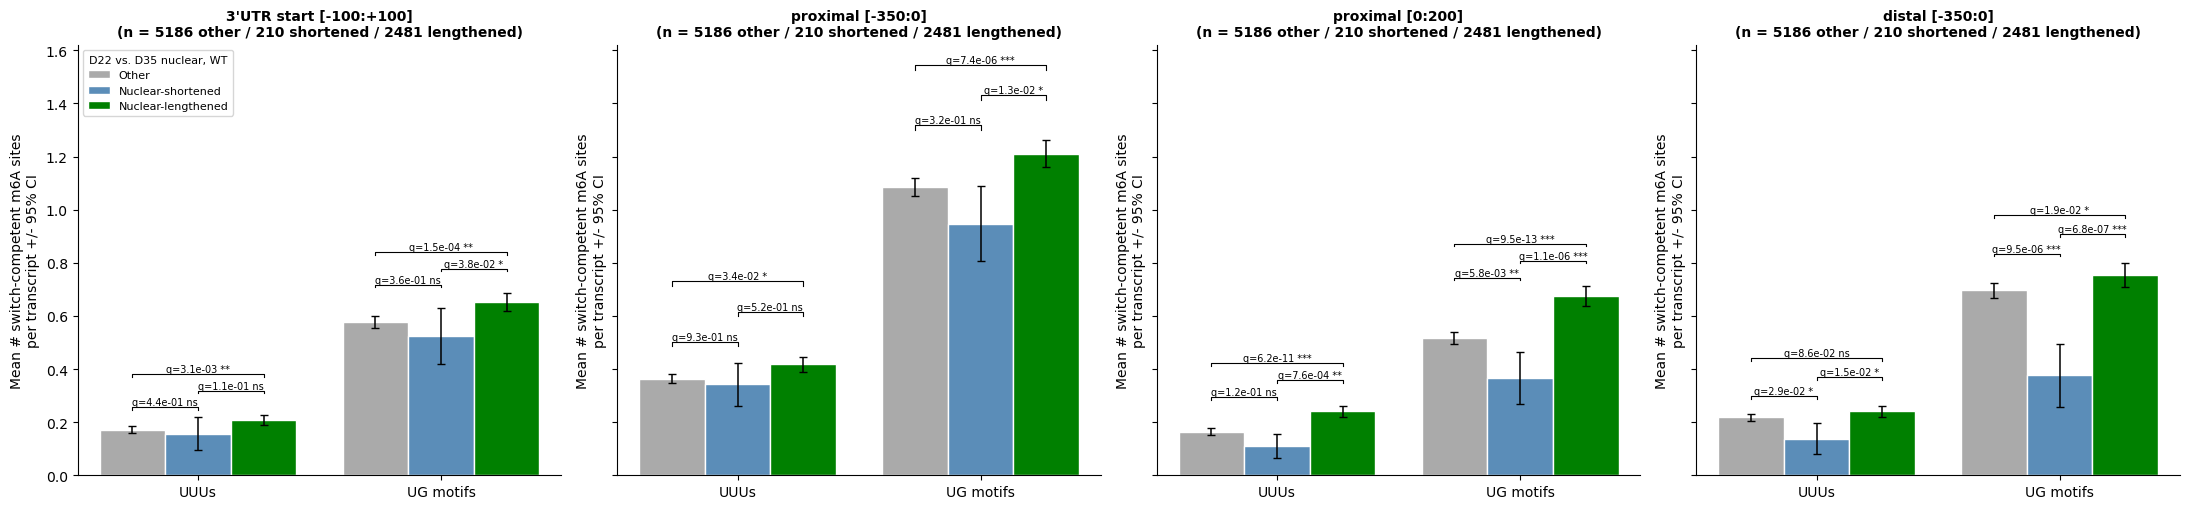

In [6]:
summ = pd.read_csv(f"{CMP}/per_transcript_summary.csv")
nl = pd.read_csv(f"{CMP}/nl_vs_other.csv")
summ_all = summ[summ["motif"] == "all"]

nuc_summ = pd.read_csv(f"{CMP}/nuc_d22_d35_per_transcript_summary.csv")
nuc_tests = pd.read_csv(f"{CMP}/nuc_d22_d35_pairwise_tests.csv")
nuc_order = ["Other", "Nuclear-shortened", "Nuclear-lengthened"]
nuc_palette = {"Other": "#aaaaaa", "Nuclear-shortened": "#5b8db8", "Nuclear-lengthened": "green"}


def three_group_barplot(summ_df, tests_df, order, palette, metric, ylabel, filename, legend_title, legend):
    """Bars = order (3 groups) for each definition, one panel per region; brackets = the three
    pairwise Mann-Whitney BH q-values (over the 3 comparisons) from tests_df (adjacent pairs low, outer pair on top)."""
    pairs = [(order[0], order[1]), (order[1], order[2]), (order[0], order[2])]
    fig, axes = plt.subplots(1, len(region_order), figsize=(5.5 * len(region_order), 5.2), sharey=True)
    width = 0.27
    for ax, region in zip(axes, region_order):
        s = summ_df[(summ_df["region"] == region) & (summ_df["metric"] == metric)]
        x = np.arange(len(definitions))
        for i, g in enumerate(order):
            rows = s[s["group"] == g].set_index("definition").reindex(definitions)
            ax.bar(x + (i - 1) * width, rows["mean"], width, yerr=rows["ci95"], capsize=3,
                   color=palette[g], edgecolor="white", label=g, error_kw={"elinewidth": 1.1})
        top_all = s.eval("mean + ci95").max()
        step = 0.09 * top_all
        for xi, d in zip(x, definitions):
            top = s[s["definition"] == d].eval("mean + ci95").max()
            for level, (a, b) in enumerate(pairs):
                t = tests_df[(tests_df["region"] == region) & (tests_df["definition"] == d)
                             & (tests_df["metric"] == metric) & (tests_df["group_a"] == a)
                             & (tests_df["group_b"] == b)].iloc[0]
                xa, xb = xi + (order.index(a) - 1) * width, xi + (order.index(b) - 1) * width
                y = top + step * (0.5 + level)
                ax.plot([xa, xa, xb, xb], [y - step * 0.15, y, y, y - step * 0.15], color="black", lw=0.8)
                ax.text((xa + xb) / 2, y, f"q={t['q_value_bh']:.1e} {stars(t['q_value_bh'])}",
                        ha="center", va="bottom", fontsize=7)
        n = s.drop_duplicates("group").set_index("group")["n"]
        # ax.set_ylim(0, top_all + step * 3.6)
        ax.set_xticks(x)
        ax.set_xticklabels(definitions)
        ax.set_title(f"{region}\n(n = {n[order[0]]} other / {n[order[1]]} shortened / "
                     f"{n[order[2]]} lengthened)", weight="bold", fontsize=10)
        ax.set_ylabel(ylabel)
        sns.despine(ax=ax)
    axes[0].legend(title=legend_title, fontsize=8, title_fontsize=8, loc="upper left")
    plt.tight_layout()
    save_figure(f"{figures_subfolder}/{filename}", legend=legend)
    plt.show()


three_group_barplot(nuc_summ, nuc_tests, nuc_order, nuc_palette, "raw_per_transcript",
                    "Mean # switch-competent m6A sites\nper transcript +/- 95% CI",
                    "barplot_switch_competent_m6A_per_transcript_nuclear_lengthened_vs_shortened_vs_other.pdf", "D22 vs. D35 nuclear, WT",
                    legend="Mean number of switch-competent m6A sites per transcript +/- 95% CI, for 3'UTR pairs lengthened (green) or shortened (blue) from D22 to D35 in CTRL nuclei and all other pairs (grey), one panel per region, both definitions. Brackets: BH q-values of the three pairwise two-sided Mann-Whitney tests (BH over the 3 tests). Switch-competent m6A site = RMBase m6A site whose most probable ViennaRNA partner (p >= 0.5) lies in a run of >= 3 U (UUUs) or in a UGU/UUG/GUG/GUU 3-mer (UG motifs). Regions (this analysis): [-100, +100] around the 3'UTR start (stop codon; windows cut at the start of the stop-codon exon so no intron is folded), [-350, 0] upstream of the pPAS, [0, +200] downstream of the pPAS, [-350, 0] upstream of the dPAS.")

### 2a'. Same, normalized by the number of m6A sites: mean per-transcript fraction of m6A sites that are switch-competent, +/- 95% CI

Transcripts with >= 1 m6A site in the window.

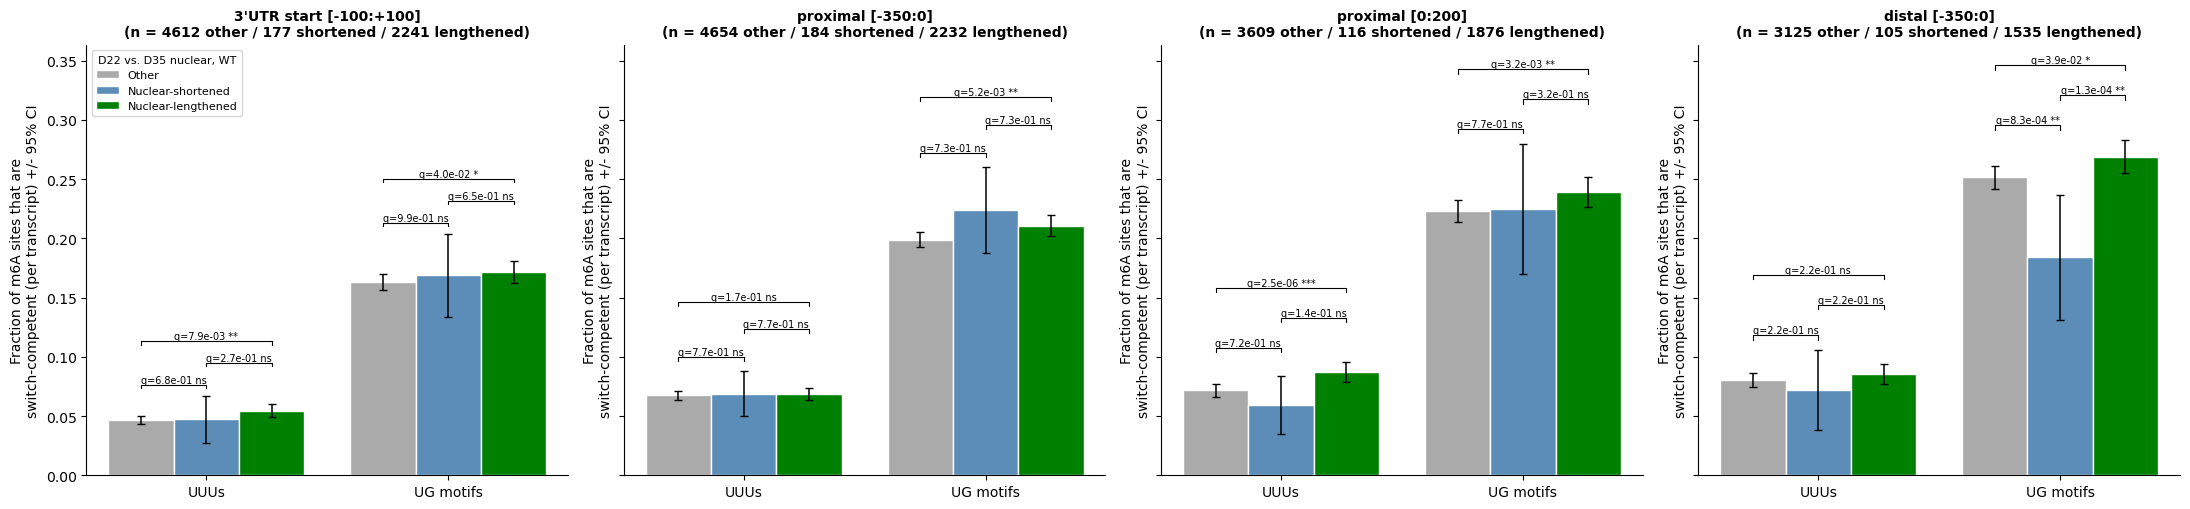

In [7]:
three_group_barplot(nuc_summ, nuc_tests, nuc_order, nuc_palette, "frac_per_m6a_site",
                    "Fraction of m6A sites that are\nswitch-competent (per transcript) +/- 95% CI",
                    "barplot_fraction_switch_competent_m6A_sites_nuclear_lengthened_vs_shortened_vs_other.pdf", "D22 vs. D35 nuclear, WT",
                    legend="Mean per-transcript fraction of m6A sites that are switch-competent +/- 95% CI (transcripts with >= 1 m6A site in the window), for 3'UTR pairs lengthened (green) or shortened (blue) from D22 to D35 in CTRL nuclei and all other pairs (grey), one panel per region, both definitions. Brackets: BH q-values of the three pairwise two-sided Mann-Whitney tests (BH over the 3 tests). Switch-competent m6A site = RMBase m6A site whose most probable ViennaRNA partner (p >= 0.5) lies in a run of >= 3 U (UUUs) or in a UGU/UUG/GUG/GUU 3-mer (UG motifs). Regions (this analysis): [-100, +100] around the 3'UTR start (stop codon; windows cut at the start of the stop-codon exon so no intron is folded), [-350, 0] upstream of the pPAS, [0, +200] downstream of the pPAS, [-350, 0] upstream of the dPAS.")

### 2b. VCP vs. CTRL at D35 (nuclear): VCP-shortened vs. VCP-lengthened vs. other pairs

Pairs shortened in VCP (`pairs_proximals_D35_Nuclear_Wildtype_vs_D35_Nuclear_VCP.csv`, 659), lengthened
in VCP (`pairs_distals_D35_Nuclear_Wildtype_vs_D35_Nuclear_VCP.csv`, 267), and all other analysed pairs of
`table_of_pairs.csv` (6,951). Same two metrics as above: raw switch-competent sites per transcript (all
transcripts), and fraction of m6A sites that are switch-competent (transcripts with >= 1 m6A site).
Brackets = BH q-values of the three pairwise two-sided Mann-Whitney tests (`vcp_d35_pairwise_tests.csv`, BH over the 3 tests).

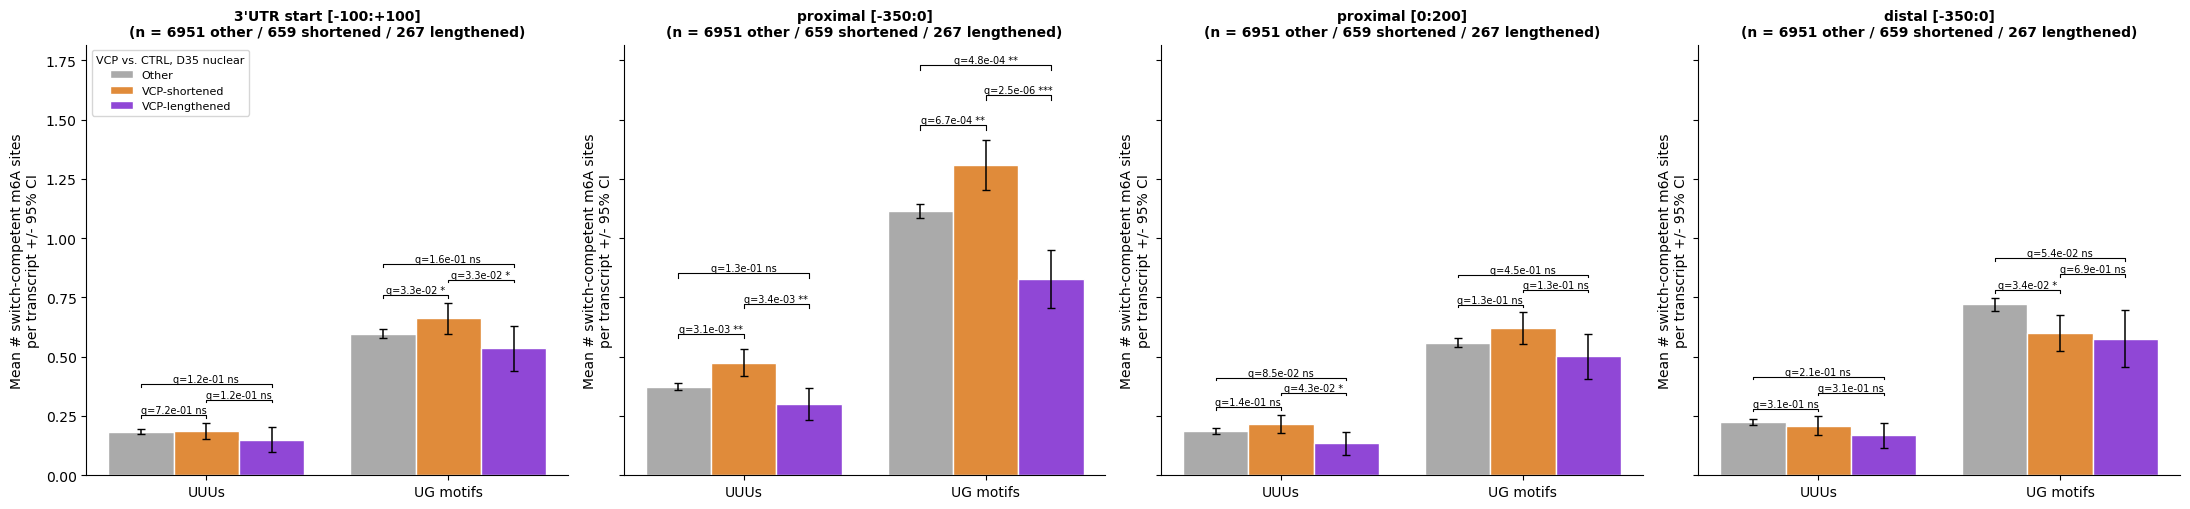

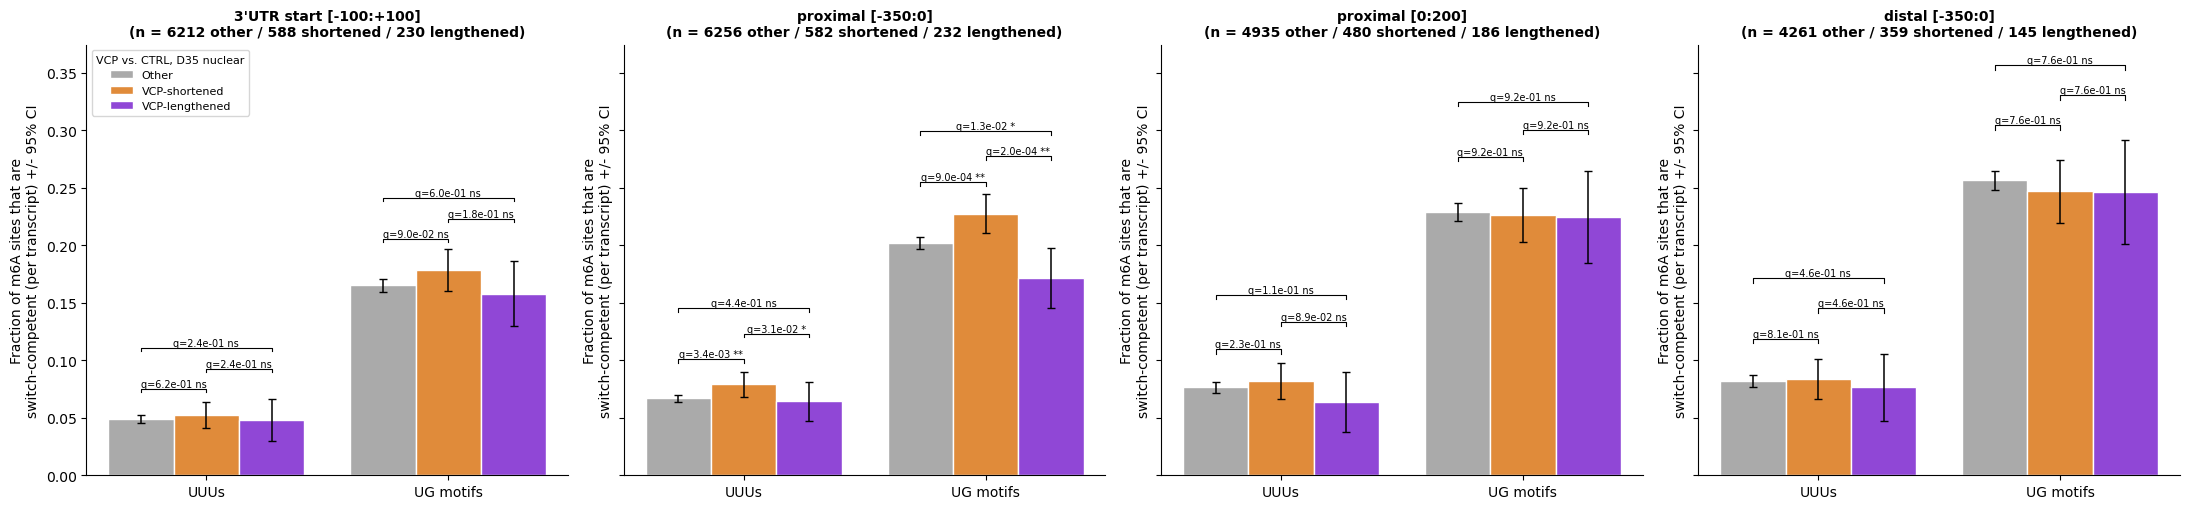

In [8]:
vcp_summ = pd.read_csv(f"{CMP}/vcp_d35_per_transcript_summary.csv")
vcp_tests = pd.read_csv(f"{CMP}/vcp_d35_pairwise_tests.csv")
vcp_order = ["Other", "VCP-shortened", "VCP-lengthened"]
vcp_palette = {"Other": "#aaaaaa", "VCP-shortened": "#e08b3a", "VCP-lengthened": "#9047d6"}

three_group_barplot(vcp_summ, vcp_tests, vcp_order, vcp_palette, "raw_per_transcript",
                    "Mean # switch-competent m6A sites\nper transcript +/- 95% CI",
                    "barplot_switch_competent_m6A_per_transcript_VCP_shortened_vs_lengthened_vs_other_D35.pdf", "VCP vs. CTRL, D35 nuclear",
                    legend="Mean number of switch-competent m6A sites per transcript +/- 95% CI, for 3'UTR pairs shortened (orange) or lengthened (purple) in VCP vs CTRL nuclei at D35 and all other pairs (grey), one panel per region, both definitions. Brackets: BH q-values of the three pairwise two-sided Mann-Whitney tests (BH over the 3 tests). Switch-competent m6A site = RMBase m6A site whose most probable ViennaRNA partner (p >= 0.5) lies in a run of >= 3 U (UUUs) or in a UGU/UUG/GUG/GUU 3-mer (UG motifs). Regions (this analysis): [-100, +100] around the 3'UTR start (stop codon; windows cut at the start of the stop-codon exon so no intron is folded), [-350, 0] upstream of the pPAS, [0, +200] downstream of the pPAS, [-350, 0] upstream of the dPAS.")
three_group_barplot(vcp_summ, vcp_tests, vcp_order, vcp_palette, "frac_per_m6a_site",
                    "Fraction of m6A sites that are\nswitch-competent (per transcript) +/- 95% CI",
                    "barplot_fraction_switch_competent_m6A_sites_VCP_shortened_vs_lengthened_vs_other_D35.pdf", "VCP vs. CTRL, D35 nuclear",
                    legend="Mean per-transcript fraction of m6A sites that are switch-competent +/- 95% CI (transcripts with >= 1 m6A site in the window), for 3'UTR pairs shortened (orange) or lengthened (purple) in VCP vs CTRL nuclei at D35 and all other pairs (grey), one panel per region, both definitions. Brackets: BH q-values of the three pairwise two-sided Mann-Whitney tests (BH over the 3 tests). Switch-competent m6A site = RMBase m6A site whose most probable ViennaRNA partner (p >= 0.5) lies in a run of >= 3 U (UUUs) or in a UGU/UUG/GUG/GUU 3-mer (UG motifs). Regions (this analysis): [-100, +100] around the 3'UTR start (stop codon; windows cut at the start of the stop-codon exon so no intron is folded), [-350, 0] upstream of the pPAS, [0, +200] downstream of the pPAS, [-350, 0] upstream of the dPAS.")

### 2c. Among the nuclear-lengthened pairs: shortened in VCP vs. not

Only the 2,481 nuclear-lengthened pairs (CTRL, D22 vs. D35 nuclear), split into those also shortened in VCP vs. CTRL at
D35 nuclear (`pairs_proximals_D35_Nuclear_Wildtype_vs_D35_Nuclear_VCP.csv`, 494) and the rest (1,987; includes 26
lengthened in VCP). Same two metrics; two-sided Mann-Whitney, BH q over all 16 tests (4 regions x 2 definitions x
2 metrics) (`nl_vcp_shortened_tests.csv`).

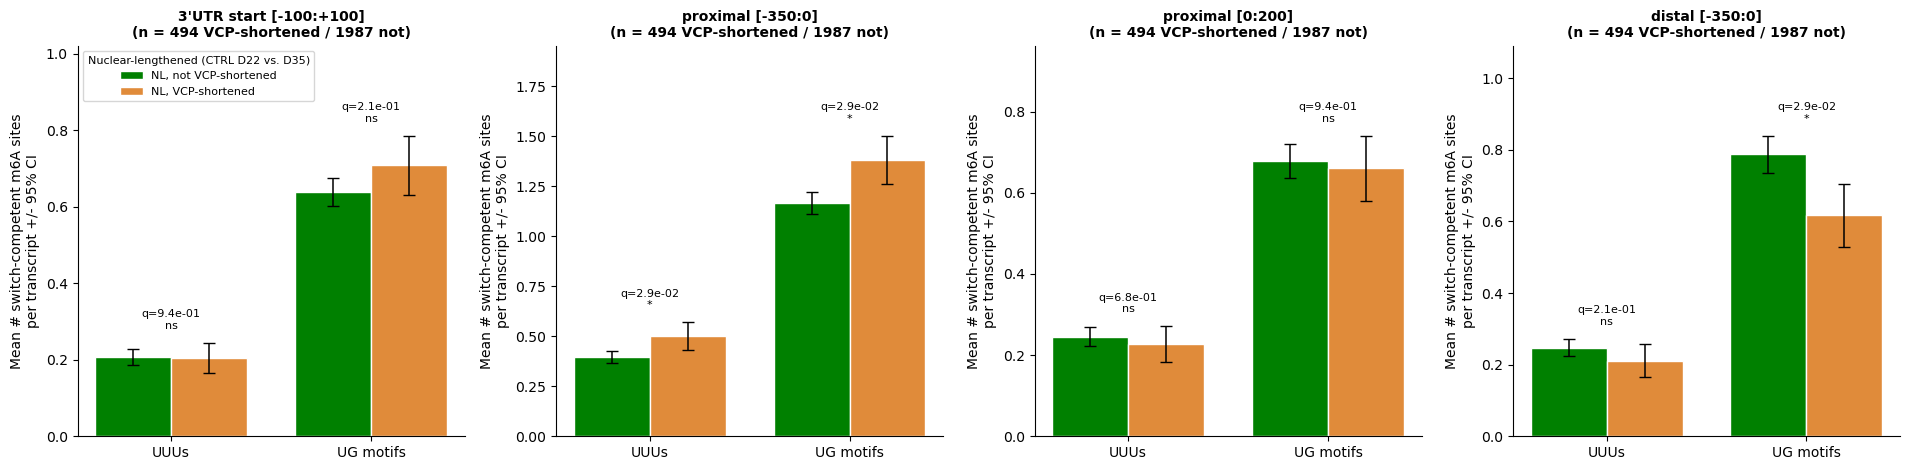

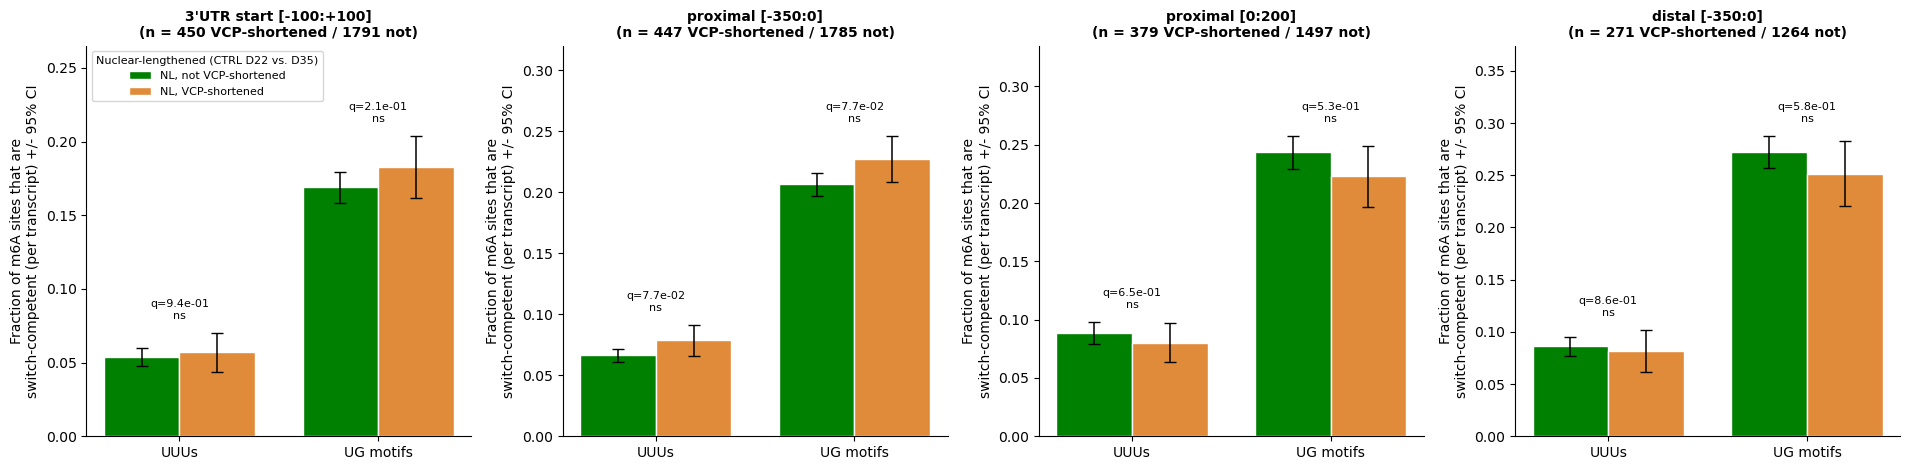

,region,definition,metric,n_a,n_b,mean_a,mean_b,p_value,q_value_bh
0,3'UTR start [-100:+100],UUUs,raw_per_transcript,494,1987,0.204453,0.207851,0.935841,0.935841
1,3'UTR start [-100:+100],UUUs,frac_per_m6a_site,450,1791,0.057117,0.053981,0.894077,0.935841
2,3'UTR start [-100:+100],UG motifs,raw_per_transcript,494,1987,0.708502,0.638148,0.090130,0.212352
3,3'UTR start [-100:+100],UG motifs,frac_per_m6a_site,450,1791,0.183042,0.169003,0.097858,0.212352
4,proximal [-350:0],UUUs,raw_per_transcript,494,1987,0.500000,0.397081,0.005492,0.029291
5,proximal [-350:0],UUUs,frac_per_m6a_site,447,1785,0.078696,0.066331,0.021691,0.077270
6,proximal [-350:0],UG motifs,raw_per_transcript,494,1987,1.382591,1.168093,0.002453,0.029291
7,proximal [-350:0],UG motifs,frac_per_m6a_site,447,1785,0.227323,0.206640,0.024147,0.077270
8,proximal [0:200],UUUs,raw_per_transcript,494,1987,0.226721,0.244590,0.513381,0.684508
9,proximal [0:200],UUUs,frac_per_m6a_site,379,1497,0.080389,0.088566,0.447524,0.650944


In [9]:
nlvs_summ = pd.read_csv(f"{CMP}/nl_vcp_shortened_per_transcript_summary.csv")
nlvs_tests = pd.read_csv(f"{CMP}/nl_vcp_shortened_tests.csv")
nlvs_order = ["NL, not VCP-shortened", "NL, VCP-shortened"]
nlvs_palette = {"NL, not VCP-shortened": "green", "NL, VCP-shortened": "#e08b3a"}


def two_group_barplot(summ_df, tests_df, order, palette, metric, ylabel, filename, legend_title, legend):
    """Two bars per definition, one panel per region; q-value (BH) of the Mann-Whitney test above each pair."""
    fig, axes = plt.subplots(1, len(region_order), figsize=(4.8 * len(region_order), 4.8))
    width = 0.38
    for ax, region in zip(axes, region_order):
        s = summ_df[(summ_df["region"] == region) & (summ_df["metric"] == metric)]
        x = np.arange(len(definitions))
        for i, g in enumerate(order):
            rows = s[s["group"] == g].set_index("definition").reindex(definitions)
            ax.bar(x + (i - 0.5) * width, rows["mean"], width, yerr=rows["ci95"], capsize=4,
                   color=palette[g], edgecolor="white", label=g, error_kw={"elinewidth": 1.1})
        top_all = s.eval("mean + ci95").max()
        for xi, d in zip(x, definitions):
            t = tests_df[(tests_df["region"] == region) & (tests_df["definition"] == d)
                         & (tests_df["metric"] == metric)].iloc[0]
            top = s[s["definition"] == d].eval("mean + ci95").max()
            ax.text(xi, top + 0.04 * top_all, f"q={t['q_value_bh']:.1e}\n{stars(t['q_value_bh'])}",
                    ha="center", va="bottom", fontsize=8)
        n = s.drop_duplicates("group").set_index("group")["n"]
        ax.set_ylim(0, top_all * 1.3)
        ax.set_xticks(x)
        ax.set_xticklabels(definitions)
        ax.set_title(f"{region}\n(n = {n[order[1]]} VCP-shortened / {n[order[0]]} not)", weight="bold", fontsize=10)
        ax.set_ylabel(ylabel)
        sns.despine(ax=ax)
    axes[0].legend(title=legend_title, fontsize=8, title_fontsize=8, loc="upper left")
    plt.tight_layout()
    save_figure(f"{figures_subfolder}/{filename}", legend=legend)
    plt.show()


two_group_barplot(nlvs_summ, nlvs_tests, nlvs_order, nlvs_palette, "raw_per_transcript",
                  "Mean # switch-competent m6A sites\nper transcript +/- 95% CI",
                  "barplot_switch_competent_m6A_per_transcript_nuclear_lengthened_VCP_shortened_vs_not.pdf", "Nuclear-lengthened (CTRL D22 vs. D35)",
                    legend="Mean number of switch-competent m6A sites per transcript +/- 95% CI, among the 3'UTR pairs lengthened from D22 to D35 in CTRL nuclei, those also shortened in VCP vs CTRL nuclei at D35 (orange) vs the rest (green), one panel per region, both definitions. q = two-sided Mann-Whitney, BH over all 12 tests (3 regions x 2 definitions x 2 metrics). Switch-competent m6A site = RMBase m6A site whose most probable ViennaRNA partner (p >= 0.5) lies in a run of >= 3 U (UUUs) or in a UGU/UUG/GUG/GUU 3-mer (UG motifs). Regions (this analysis): [-100, +100] around the 3'UTR start (stop codon; windows cut at the start of the stop-codon exon so no intron is folded), [-350, 0] upstream of the pPAS, [0, +200] downstream of the pPAS, [-350, 0] upstream of the dPAS.")
two_group_barplot(nlvs_summ, nlvs_tests, nlvs_order, nlvs_palette, "frac_per_m6a_site",
                  "Fraction of m6A sites that are\nswitch-competent (per transcript) +/- 95% CI",
                  "barplot_fraction_switch_competent_m6A_sites_nuclear_lengthened_VCP_shortened_vs_not.pdf", "Nuclear-lengthened (CTRL D22 vs. D35)",
                    legend="Mean per-transcript fraction of m6A sites that are switch-competent +/- 95% CI (transcripts with >= 1 m6A site in the window), among the 3'UTR pairs lengthened from D22 to D35 in CTRL nuclei, those also shortened in VCP vs CTRL nuclei at D35 (orange) vs the rest (green), one panel per region, both definitions. q = two-sided Mann-Whitney, BH over all 12 tests (3 regions x 2 definitions x 2 metrics). Switch-competent m6A site = RMBase m6A site whose most probable ViennaRNA partner (p >= 0.5) lies in a run of >= 3 U (UUUs) or in a UGU/UUG/GUG/GUU 3-mer (UG motifs). Regions (this analysis): [-100, +100] around the 3'UTR start (stop codon; windows cut at the start of the stop-codon exon so no intron is folded), [-350, 0] upstream of the pPAS, [0, +200] downstream of the pPAS, [-350, 0] upstream of the dPAS.")
nlvs_tests[["region", "definition", "metric", "n_a", "n_b", "mean_a", "mean_b", "p_value", "q_value_bh"]]

## 3. CLIP: do the candidate RBPs prefer switch-linked elements?

Region 0 (3'UTR start) has no candidate list: its figures highlight its top 10 datasets among all CLIP
datasets instead (q < 0.05, highest fold change; replicates of an RBP counted separately; section 3b test). R1-R3: each region is tested with its own candidate list (see table above), so an RBP can appear in
one region and not another (grey = not tested in that region). Effect size = fold change
(observed / expected fraction of the RBP's crosslinks in switch-linked elements; 1 = no preference);
q = BH within region x element type.

In [10]:
ALL = f"{ROOT}/clip_all_datasets"
clip_all = pd.read_csv(f"{ALL}/clip_enrichment_all_datasets.csv")

# Highlighted datasets per region x element: the region's regulators of lengthening; for R0 (3'UTR start, no
# candidate list) its top TOP_N datasets instead = the TOP_N significant (q < 0.05) datasets with the highest fold
# change (replicates / cell lines of the same RBP count separately and are labelled with their assay).
TOP_N = 10
clip_all_region_order = [r for r in region_order if r in set(clip_all["region"])]   # R0, R1, R2, R3
clip_all["highlight"] = clip_all["is_candidate"]
for (region, element), g in clip_all.groupby(["region", "element"]):
    if not g["is_candidate"].any():
        top = g[g["q_value_bh"] < 0.05].nlargest(TOP_N, "fold_change")
        clip_all.loc[top.index, "highlight"] = True
# point labels: the RBP, or the full dataset name when the same RBP is highlighted twice in a region x element
clip_all["label"] = clip_all["RBP"]
hl = clip_all[clip_all["highlight"]]
dup = hl.duplicated(["region", "element", "RBP"], keep=False)
clip_all.loc[hl.index[dup], "label"] = hl.loc[dup, "dataset"]


def has_candidates(region):
    return bool(clip_all.loc[clip_all["region"] == region, "is_candidate"].any())


def highlight_name(region):
    return "regulators of lengthening" if has_candidates(region) else f"top {TOP_N} datasets (q < 0.05, highest FC)"


def r_label(region):
    return f"R{region_order.index(region)}"   # R0 = 3'UTR start, R1-R3 as before


clip = pd.read_csv(f"{CMP}/clip_enrichment_all_regions.csv")
counts = clip.assign(sig=clip["q_value_bh"] < 0.05).groupby(["region", "element"], sort=False) \
             .agg(n_rbps=("RBP", "size"), n_significant_q05=("sig", "sum"),
                  expected_rate=("expected_rate", "first"), candidates=("candidates", "first"))
counts

n_rbps  n_significant_q05  expected_rate  \
region            element                                               
proximal [-350:0] U-tracts       11                 10       0.049821   
                  GU motifs      11                 11       0.084989   
proximal [0:200]  U-tracts       17                 15       0.035776   
                  GU motifs      17                 17       0.070340   
distal [-350:0]   U-tracts       15                 15       0.023391   
                  GU motifs      15                 15       0.047682   

                                                             candidates  
region            element                                                
proximal [-350:0] U-tracts   candidates_lengthening_in_CTRL_region1.csv  
                  GU motifs  candidates_lengthening_in_CTRL_region1.csv  
proximal [0:200]  U-tracts   candidates_lengthening_in_CTRL_region2.csv  
                  GU motifs  candidates_lengthening_in_CTRL_region2.csv  
distal [-350:0]   U-tracts   candidates_lengthening_in_CTRL_region3.csv  
                  GU motifs  candidates_lengthening_in_CTRL_region3.csv

### Which RBPs prefer switch-linked elements? Fold change vs. significance

x = fold change = observed / expected fraction of the RBP's crosslinks that land in
switch-linked elements); y = -log10(q), the binomial p BH-corrected over the region's candidates (within
region x element). Filled = q < 0.05; dotted line = q = 0.05.

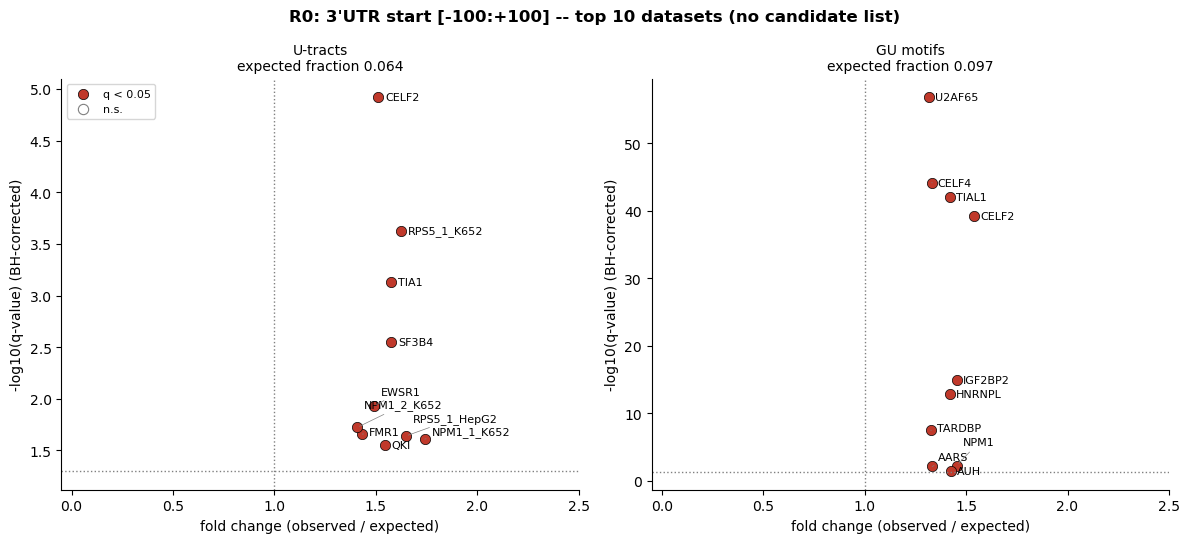

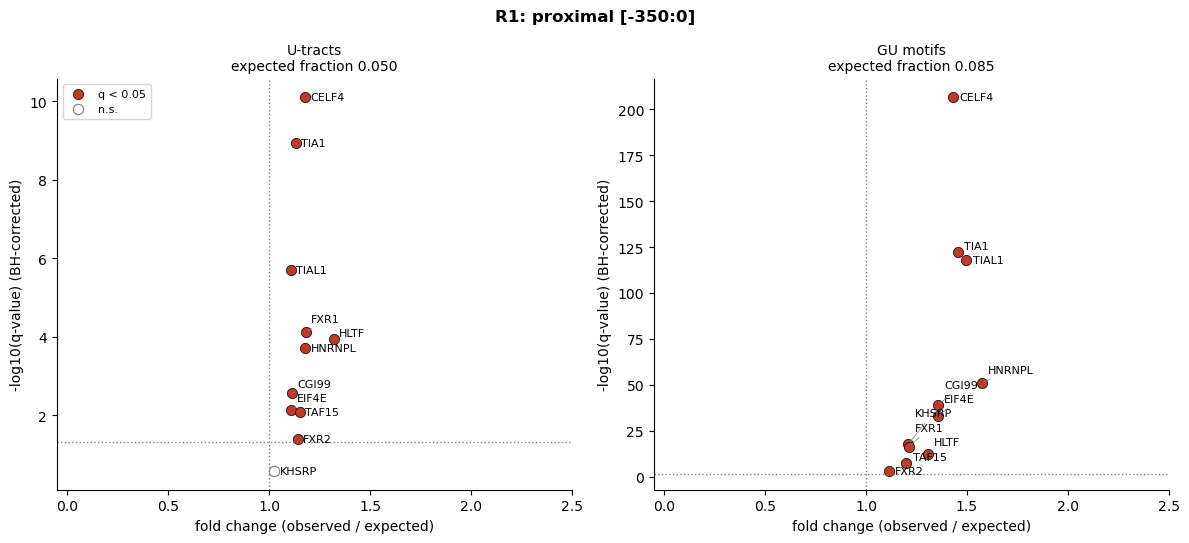

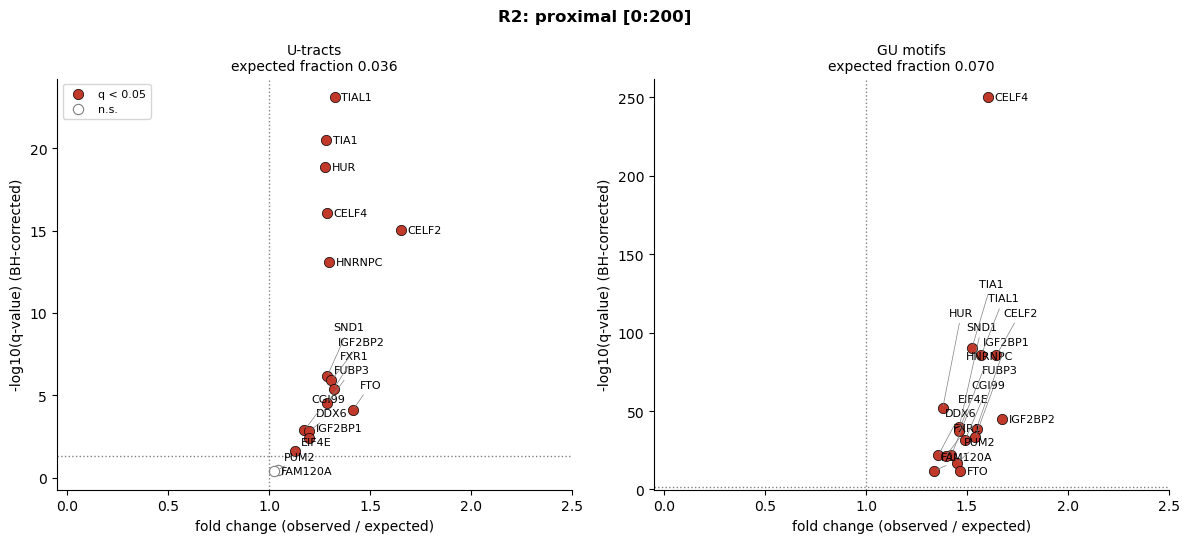

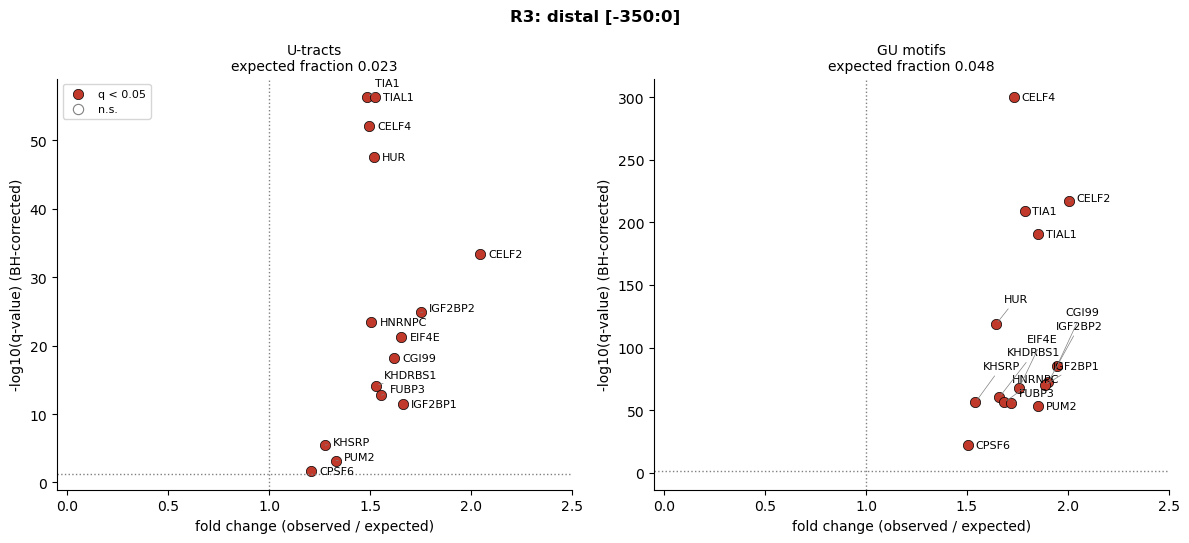

In [11]:
P_FLOOR = 1e-300
import numpy as np


def label_points(ax, xs, ys, labels, fontsize=8, min_gap_frac=0.035):
    """Label points to their right; labels whose points are close in x are spread vertically
    (greedy, bottom to top) so they don't overlap, with a thin leader line when moved."""
    y0, y1 = ax.get_ylim()
    x0, x1 = ax.get_xlim()
    gap, xwin = min_gap_frac * (y1 - y0), 0.12 * (x1 - x0)
    placed = []  # (x, y_label)
    for k in np.argsort(ys):
        x, y = xs[k], ys[k]
        ly = y
        for px, py in sorted(placed, key=lambda t: t[1]):
            if abs(px - x) < xwin and abs(py - ly) < gap:
                ly = py + gap
        placed.append((x, ly))
        moved = abs(ly - y) > 1e-9
        ax.annotate(labels[k], (x, y), xytext=(x + 0.015 * (x1 - x0), ly), textcoords="data",
                    fontsize=fontsize, va="center",
                    arrowprops=dict(arrowstyle="-", color="grey", lw=0.5) if moved else None)
# same y-axis range across regions within each row (element type)
row_ymax = {e: (-np.log10(clip.loc[clip["element"] == e, "q_value_bh"].clip(lower=P_FLOOR))).max() * 1.12
            for e in ["U-tracts", "GU motifs"]}
# one figure per region: R0 (top 10 datasets of the all-dataset test, no candidate list), R1-R3 (candidates)
for region in clip_all_region_order:
    r_idx = region_order.index(region)
    fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
    for ax, element in zip(axes, ["U-tracts", "GU motifs"]):
        if has_candidates(region):
            d = clip[(clip["region"] == region) & (clip["element"] == element)].copy()
        else:   # R0: its top-10 datasets, q from the all-dataset test (BH over 338)
            d = clip_all[(clip_all["region"] == region) & (clip_all["element"] == element) & clip_all["highlight"]].copy()
        d["fc"] = d["observed_rate"] / d["expected_rate"]
        d["capped"] = d["p_value"] < P_FLOOR
        d["neg_log10_p"] = -np.log10(d["q_value_bh"].clip(lower=P_FLOOR))   # y = -log10(q)
        sig = d["q_value_bh"] < 0.05
        for capped, marker in [(False, "o"), (True, "o")]:
            m = d["capped"] == capped
            ax.scatter(d.loc[m & sig, "fc"], d.loc[m & sig, "neg_log10_p"], s=55, marker=marker,
                       color="#c0392b", edgecolor="black", linewidth=0.5, label="q < 0.05" if not capped else None)
            ax.scatter(d.loc[m & ~sig, "fc"], d.loc[m & ~sig, "neg_log10_p"], s=55, marker=marker,
                       facecolor="white", edgecolor="grey", linewidth=0.8, label="n.s." if not capped else None)
        ax.set_xlim(min(-0.05, d["fc"].min() - 0.05), d["fc"].max() * 1.25 + 0.05)
        #ax.set_ylim(0, row_ymax[element])
        label_points(ax, d["fc"].values, d["neg_log10_p"].values, (d["label"] if "label" in d else d["RBP"]).values)
        ax.axvline(1, color="grey", linestyle=":", linewidth=1)
        ax.axhline(-np.log10(0.05), color="grey", linestyle=":", linewidth=1)
        ax.set_xlabel("fold change (observed / expected)")
        ax.set_ylabel("-log10(q-value) (BH-corrected)")
        ax.set_title(f"{element}\nexpected fraction {d['expected_rate'].iloc[0]:.3f}", fontsize=10)
        ax.set_xlim(-0.05, 2.5)
        sns.despine(ax=ax)
    axes[0].legend(fontsize=8, loc="upper left")
    fig.suptitle(f"R{r_idx}: {region}" + ("" if has_candidates(region) else f" -- top {TOP_N} datasets (no candidate list)"), weight="bold")
    plt.tight_layout()
    save_figure(f"{figures_subfolder}/scatter_candidate_CLIP_preference_switch_elements_R{r_idx}.pdf",
                legend=(f"R{r_idx} ({region}): preference of the CLIP crosslinks of each R{r_idx} regulator of lengthening "
                        f"(Figure_regulators_lengthening.ipynb) for m6A-switch-linked elements, U-tracts (left) "
                        "and GU motifs (right). x = fold change, observed / expected fraction of the RBP's crosslinks on that "
                        "element type that fall in switch-linked elements (dotted line = 1, no preference); y = -log10(q), "
                        "one-sided binomial test, BH over the region's candidates. Red = q < 0.05; dotted line = q 0.05."
                        if has_candidates(region) else
                        f"R0 ({region}; windows cut at the start of the stop-codon exon), no candidate list: the {TOP_N} CLIP "
                        "datasets with the strongest preference for m6A-switch-linked elements among all 338 (q < 0.05, highest "
                        "fold change; replicates of an RBP counted separately), U-tracts (left) and GU motifs (right). x = fold change, "
                        "observed / expected fraction of the RBP's crosslinks on that element type that fall in switch-linked "
                        "elements (dotted line = 1); y = -log10(q), one-sided binomial test, BH over the 338 datasets. "
                        "Dotted line = q 0.05."))
    plt.show()

### 3b. Where do the candidates sit among all CLIP datasets?

The same test run on every CLIP dataset in `CLIP_for_raphaelle/hg38` (338 datasets, 127 RBPs: eCLIP K562 177,
HepG2 140, iCLIP 21), in every region x element type (`scripts/m6a_switch/clip_enrichment_all_datasets.py`, pipeline steps `m6a_regions_clip_*`;
results in `ROOT/clip_all_datasets/`). Candidate rows reproduce the per-region results above exactly.
Candidates = the region's own candidate list; for R0 (no list) the top 10 datasets (q < 0.05, highest FC) are highlighted instead. `candidates_vs_rest.csv`: one-sided Mann-Whitney (BH q over the 6 region x element tests), are the candidates'
fold changes higher than those of all other datasets (including other replicates / cell lines of the same RBP)?
Two tiny datasets with 0 crosslinks in switch-linked U-tracts have FC = 0. Dotted vertical line = FC 1 (no preference).

In [12]:
ALL = f"{ROOT}/clip_all_datasets"
# clip_all (with the "highlight" column) is loaded at the start of section 3
cand_vs_rest = pd.read_csv(f"{ALL}/candidates_vs_rest.csv")
elements = ["U-tracts", "GU motifs"]



cand_vs_rest

,region,element,n_candidates,n_rest,median_fc_candidates,median_fc_rest,median_percentile_candidates,frac_rest_significant_q05,frac_candidates_significant_q05,test,statistic,p_value,median_neglog10p_candidates,median_neglog10p_rest,statistic_neglog10p,p_value_neglog10p,q_value_bh,q_value_bh_neglog10p
0,distal [-350:0],GU motifs,15,323,1.758932,1.610471,75.739645,0.956656,1.000000,Mann-Whitney U (candidates > rest),3529.0,1.397156e-03,70.170677,13.060995,4564.0,3.580702e-09,2.794312e-03,1.074211e-08
1,distal [-350:0],U-tracts,15,323,1.526615,1.521510,50.591716,0.783282,1.000000,Mann-Whitney U (candidates > rest),2509.0,4.080915e-01,21.488925,3.485918,4256.0,3.624440e-07,4.080915e-01,7.248880e-07
2,proximal [-350:0],GU motifs,11,327,1.354834,1.114040,94.970414,0.541284,1.000000,Mann-Whitney U (candidates > rest),3178.0,7.592652e-06,33.132771,1.973755,3285.0,1.568446e-06,2.277796e-05,2.352669e-06
3,proximal [-350:0],U-tracts,11,327,1.141992,1.106388,60.650888,0.351682,0.818182,Mann-Whitney U (candidates > rest),2177.0,1.178501e-01,3.980541,1.001362,2880.0,3.480074e-04,1.414201e-01,3.480074e-04
4,proximal [0:200],GU motifs,17,321,1.467307,1.239034,90.828402,0.666667,1.000000,Mann-Whitney U (candidates > rest),5008.0,3.229642e-09,37.586765,3.337265,5195.0,1.685445e-10,1.937785e-08,1.011267e-09
5,proximal [0:200],U-tracts,17,321,1.287157,1.215749,65.680473,0.454829,0.882353,Mann-Whitney U (candidates > rest),3200.0,1.151483e-01,5.681165,1.404958,4434.0,7.044052e-06,1.414201e-01,8.452863e-06


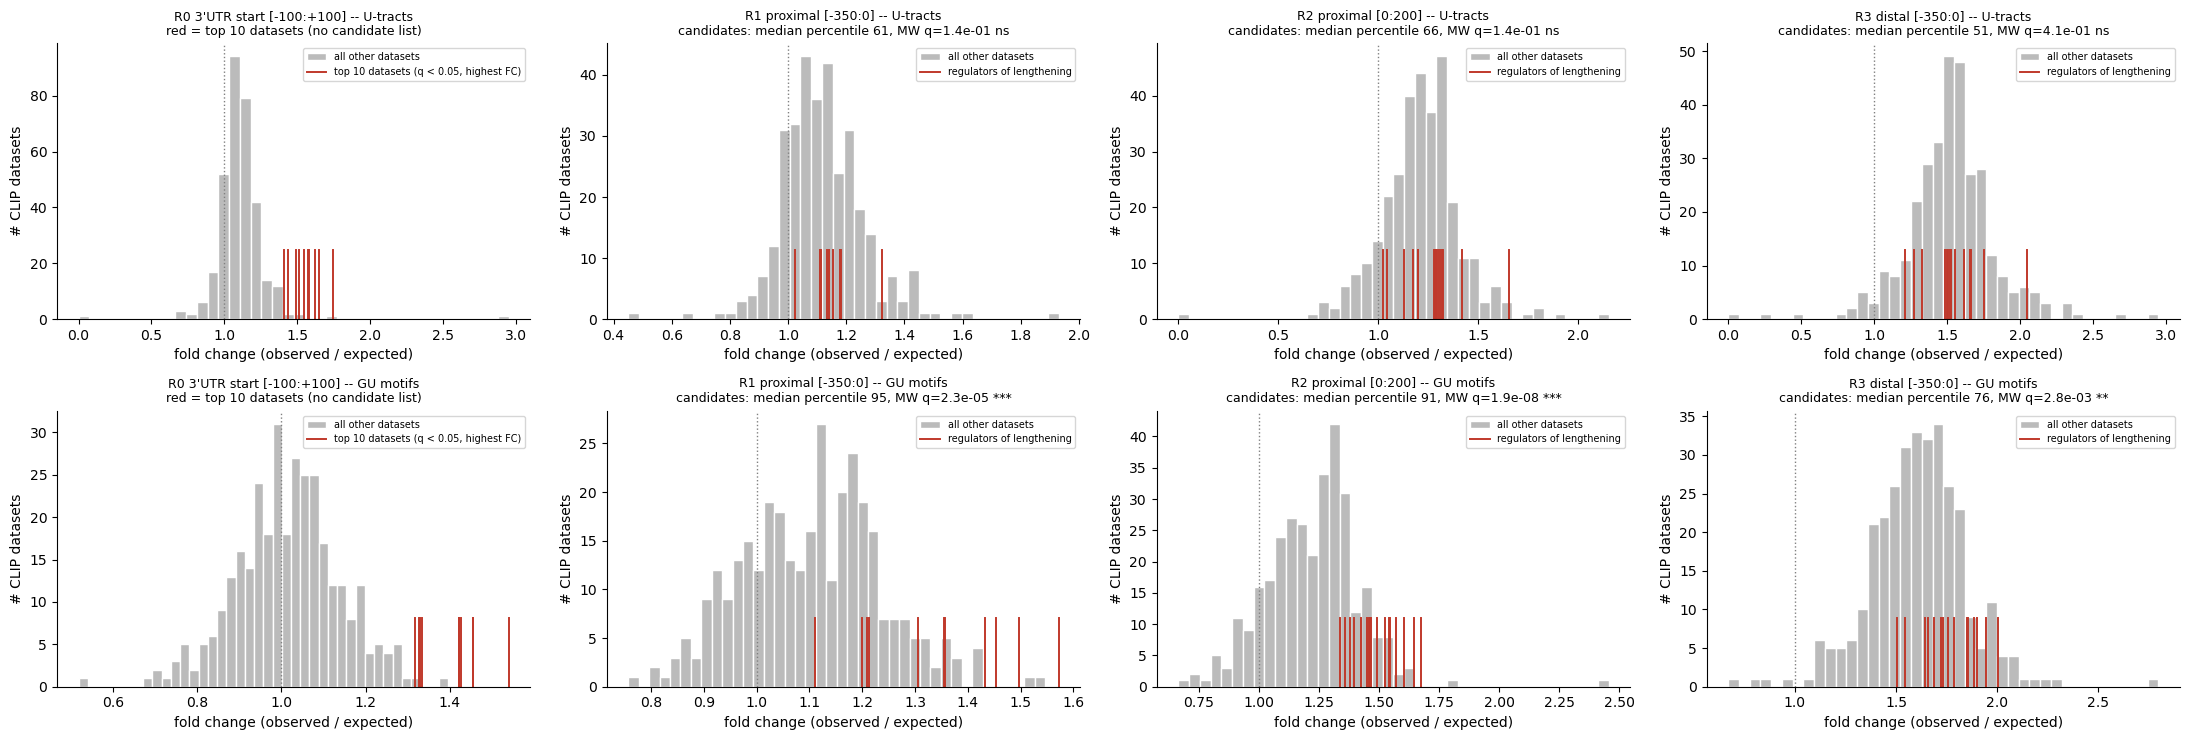

In [13]:
# distribution of FC over all 338 datasets, candidates as red ticks
fig, axes = plt.subplots(len(elements), len(clip_all_region_order), figsize=(5.5 * len(clip_all_region_order), 7.5))
for col, region in enumerate(clip_all_region_order):
    for row, element in enumerate(elements):
        ax = axes[row, col]
        d = clip_all[(clip_all["region"] == region) & (clip_all["element"] == element)].copy()
        d["fc"] = d["fold_change"]
        ax.hist(d.loc[~d["highlight"], "fc"], bins=40, color="#bbbbbb", edgecolor="white", label="all other datasets")
        ymax = ax.get_ylim()[1]
        for fc in d.loc[d["highlight"], "fc"]:
            ax.plot([fc, fc], [0, ymax * 0.25], color="#c0392b", lw=1.4)
        ax.plot([], [], color="#c0392b", lw=1.4, label=highlight_name(region))
        ax.axvline(1, color="grey", linestyle=":", linewidth=1)
        if has_candidates(region):
            r = cand_vs_rest[(cand_vs_rest["region"] == region) & (cand_vs_rest["element"] == element)].iloc[0]
            ax.set_title(f"{r_label(region)} {region} -- {element}\ncandidates: median percentile "
                         f"{r['median_percentile_candidates']:.0f}, MW q={r['q_value_bh']:.1e} {stars(r['q_value_bh'])}", fontsize=9)
        else:
            ax.set_title(f"{r_label(region)} {region} -- {element}\nred = top {TOP_N} datasets (no candidate list)", fontsize=9)
        ax.legend(fontsize=7, loc="upper right")
        ax.set_xlabel("fold change (observed / expected)")
        ax.set_ylabel("# CLIP datasets")
        sns.despine(ax=ax)
plt.tight_layout()
save_figure(f"{figures_subfolder}/histogram_CLIP_preference_switch_elements_all_datasets_vs_candidates.pdf",
            legend="Fold change (observed / expected share of crosslinks in m6A-switch-linked elements) of all 338 CLIP "
                   "datasets (grey histogram) per region (columns) and element type (rows: U-tracts, GU motifs); red "
                   "ticks = the region's regulators of lengthening (R1-R3) or, for R0 (3'UTR start; no candidate list), its "
                   "top 10 datasets (q < 0.05, highest fold change). Titles (R1-R3): candidates' median percentile and "
                   "one-sided Mann-Whitney q (candidates > rest; BH over the 6 region x element tests). Dotted line = FC 1.")
plt.show()

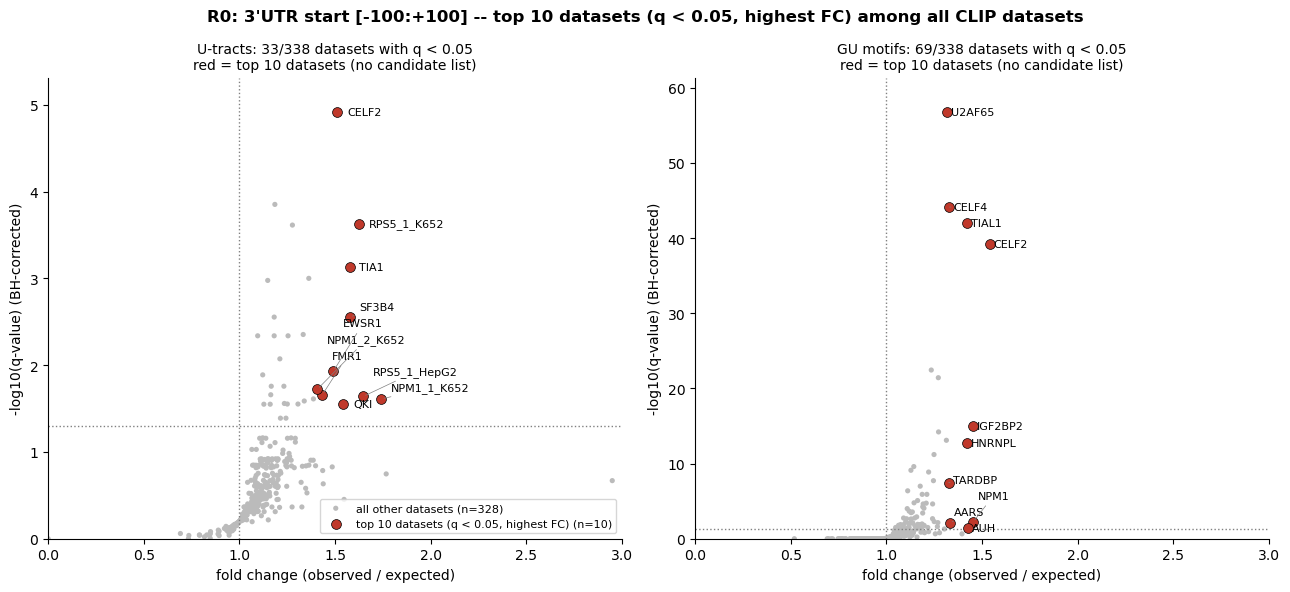

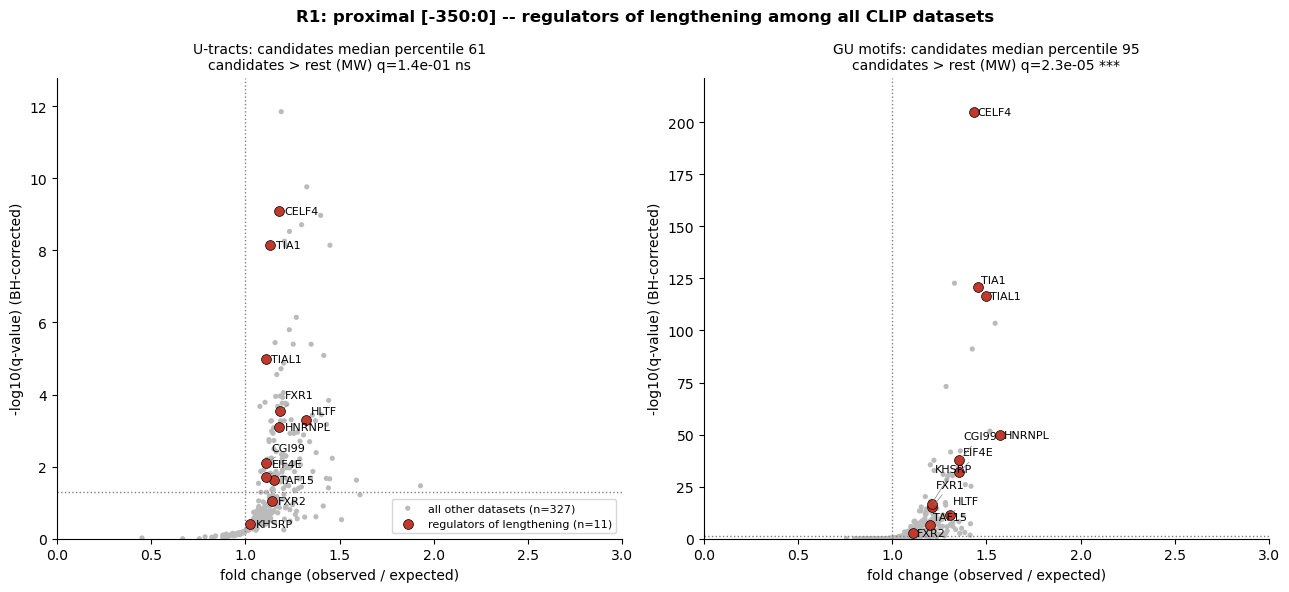

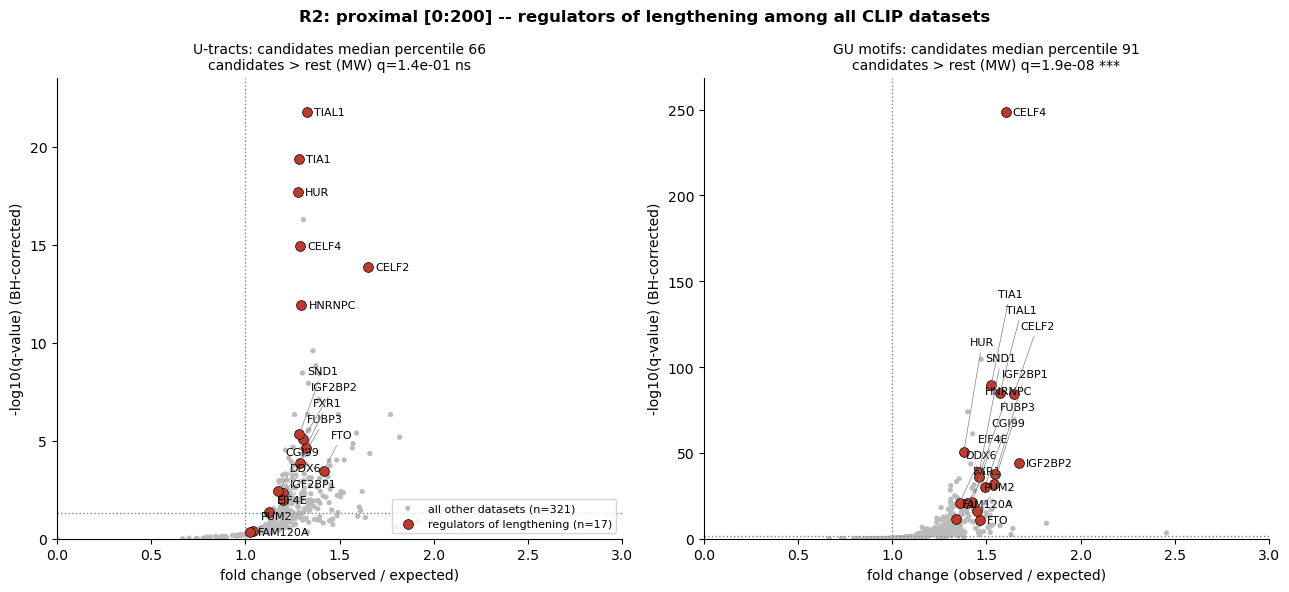

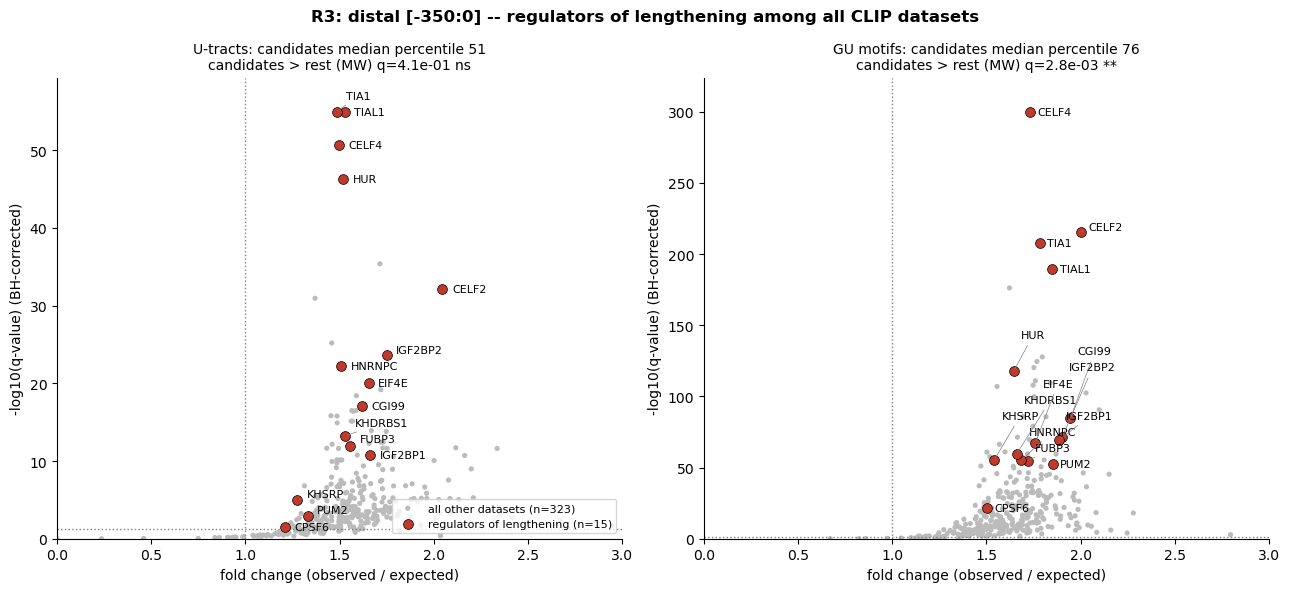

In [14]:
# fold change vs. significance for all datasets (grey), candidates in red and labelled; one figure per region
for region in clip_all_region_order:
    r_idx = region_order.index(region)
    fig, axes = plt.subplots(1, 2, figsize=(13, 6))
    for ax, element in zip(axes, elements):
        d = clip_all[(clip_all["region"] == region) & (clip_all["element"] == element)].copy()
        d["fc"] = d["fold_change"]
        d["neg_log10_p"] = -np.log10(d["q_value_bh"].clip(lower=P_FLOOR))   # y = -log10(q)
        rest, cand = d[~d["highlight"]], d[d["highlight"]]
        ax.scatter(rest["fc"], rest["neg_log10_p"], s=14, color="#bbbbbb", edgecolor="none",
                   label=f"all other datasets (n={len(rest)})")
        ax.scatter(cand["fc"], cand["neg_log10_p"], s=50, color="#c0392b", edgecolor="black", linewidth=0.5,
                   label=f"{highlight_name(region)} (n={len(cand)})", zorder=3)
        ax.set_xlim(d["fc"].min() - 0.1, d["fc"].max() + 0.35)
        ax.set_ylim(0, d["neg_log10_p"].max() * 1.08)
        label_points(ax, cand["fc"].values, cand["neg_log10_p"].values, cand["label"].values)
        ax.axvline(1, color="grey", linestyle=":", linewidth=1)
        ax.axhline(-np.log10(0.05), color="grey", linestyle=":", linewidth=1)
        if has_candidates(region):
            r = cand_vs_rest[(cand_vs_rest["region"] == region) & (cand_vs_rest["element"] == element)].iloc[0]
            ax.set_title(f"{element}: candidates median percentile {r['median_percentile_candidates']:.0f}\n"
                         f"candidates > rest (MW) q={r['q_value_bh']:.1e} {stars(r['q_value_bh'])}", fontsize=10)
        else:
            ax.set_title(f"{element}: {(d['q_value_bh'] < 0.05).sum()}/{len(d)} datasets with q < 0.05\n"
                         f"red = top {TOP_N} datasets (no candidate list)", fontsize=10)
        ax.set_xlabel("fold change (observed / expected)")
        ax.set_ylabel("-log10(q-value) (BH-corrected)")
        sns.despine(ax=ax)
        ax.set_xlim(0, 3)
    axes[0].legend(fontsize=8, loc="lower right")
    fig.suptitle(f"R{r_idx}: {region} -- {highlight_name(region)} among all CLIP datasets", weight="bold")
    plt.tight_layout()
    save_figure(f"{figures_subfolder}/scatter_CLIP_preference_switch_elements_all_datasets_R{r_idx}.pdf",
                legend=f"R{r_idx} ({region}): fold change (observed / expected share of crosslinks in m6A-switch-linked "
                       "elements) vs -log10(q) (one-sided binomial, BH over the 338 datasets within region x element) for "
                       "all CLIP datasets (grey) and, in red and labelled, " + (
                       "the region's regulators of lengthening; titles: candidates' median percentile and one-sided "
                       "Mann-Whitney q (candidates > rest). " if has_candidates(region) else
                       f"the {TOP_N} datasets with the strongest preference (q < 0.05, highest fold change; replicates of an "
                       "RBP counted separately; R0 = 3'UTR start, no candidate list). ") + "U-tracts (left) and GU motifs (right). "
                       "Dotted lines = FC 1 and q 0.05.")
    plt.show()

In [15]:
# each candidate's rank among the 338 datasets (1 = highest FC) and percentile, per region x element
cand_ranks = (clip_all[clip_all["is_candidate"]]
              .assign(rank_pct=lambda d: d["rank_fc"].astype(int).astype(str) + " (" + d["percentile_fc"].round(0).astype(int).astype(str) + "%)")
              .pivot_table(index=["region", "RBP", "dataset"], columns="element", values="rank_pct", aggfunc="first")
              .reindex(columns=elements))
cand_ranks

element                                              U-tracts  GU motifs
region            RBP     dataset                                       
distal [-350:0]   CELF2   all-Celf2-293Flp_iCLIP     15 (96%)   14 (96%)
                  CELF4   all-Celf4-FlpIn293_iCLIP  194 (43%)   97 (72%)
                  CGI99   all-CGI99-FlpIn293_iCLIP  107 (69%)   26 (93%)
                  CPSF6   CPSF6_2_K652              304 (10%)  239 (30%)
                  EIF4E   all-eIF4E-FlpIn293_iCLIP   91 (73%)   83 (76%)
                  FUBP3   FUBP3_1_HepG2             151 (56%)  106 (69%)
                  HNRNPC  hnrnpc-bestof_iCLIP       183 (46%)  132 (61%)
                  HUR     all-HuR-FlpIn293_iCLIP    172 (49%)  155 (54%)
                  IGF2BP1 IGF2BP1_1_K652             88 (74%)   35 (90%)
                  IGF2BP2 all-IGF2BP2-Hela_iCLIP     52 (85%)   30 (91%)
                  KHDRBS1 KHDRBS1_2_K652            166 (51%)  145 (57%)
                  KHSRP   KHSRP_1_K652              289 (15%)  222 (35%)
                  PUM2    PUM2_1_K652               271 (20%)   41 (88%)
                  TIA1    all-TIA1-Hela_iCLIP       205 (40%)   69 (80%)
                  TIAL1   all-TIAL1-Hela_iCLIP      168 (51%)   42 (88%)
proximal [-350:0] CELF4   all-Celf4-FlpIn293_iCLIP  100 (71%)    6 (99%)
                  CGI99   all-CGI99-FlpIn293_iCLIP  168 (51%)   17 (95%)
                  EIF4E   all-eIF4E-FlpIn293_iCLIP  172 (49%)   18 (95%)
                  FXR1    FXR1_2_K652                97 (72%)   70 (80%)
                  FXR2    FXR2_1_K652               134 (61%)  175 (49%)
                  HLTF    HLTF_1_K652                25 (93%)   29 (92%)
                  HNRNPL  all-hnRNPL-Hela_iCLIP      99 (71%)   1 (100%)
                  KHSRP   KHSRP_1_K652              258 (24%)   74 (78%)
                  TAF15   TAF15_1_K652              118 (65%)   86 (75%)
                  TIA1    all-TIA1-Hela_iCLIP       145 (57%)    5 (99%)
                  TIAL1   all-TIAL1-Hela_iCLIP      170 (50%)    4 (99%)
proximal [0:200]  CELF2   all-Celf2-293Flp_iCLIP      7 (98%)    4 (99%)
                  CELF4   all-Celf4-FlpIn293_iCLIP  115 (66%)    8 (98%)
                  CGI99   all-CGI99-FlpIn293_iCLIP  209 (38%)   28 (92%)
                  DDX6    DDX6_2_K652               187 (45%)   82 (76%)
                  EIF4E   all-eIF4E-FlpIn293_iCLIP  246 (28%)   52 (85%)
                  FAM120A FAM120A_1_K652            293 (14%)   98 (71%)
                  FTO     FTO_1_K652                 38 (89%)   32 (91%)
                  FUBP3   FUBP3_1_HepG2             116 (66%)   13 (96%)
                  FXR1    FXR1_2_K652                84 (75%)   59 (83%)
                  HNRNPC  hnrnpc-bestof_iCLIP       106 (69%)   38 (89%)
                  HUR     all-HuR-FlpIn293_iCLIP    121 (64%)   67 (80%)
                  IGF2BP1 IGF2BP1_1_K652            191 (44%)   12 (97%)
                  IGF2BP2 all-IGF2BP2-Hela_iCLIP     95 (72%)    3 (99%)
                  PUM2    PUM2_1_K652               285 (16%)   42 (88%)
                  SND1    SND1_2_K652               117 (66%)   35 (90%)
                  TIA1    all-TIA1-Hela_iCLIP       120 (65%)   18 (95%)
                  TIAL1   all-TIAL1-Hela_iCLIP       80 (77%)   11 (97%)

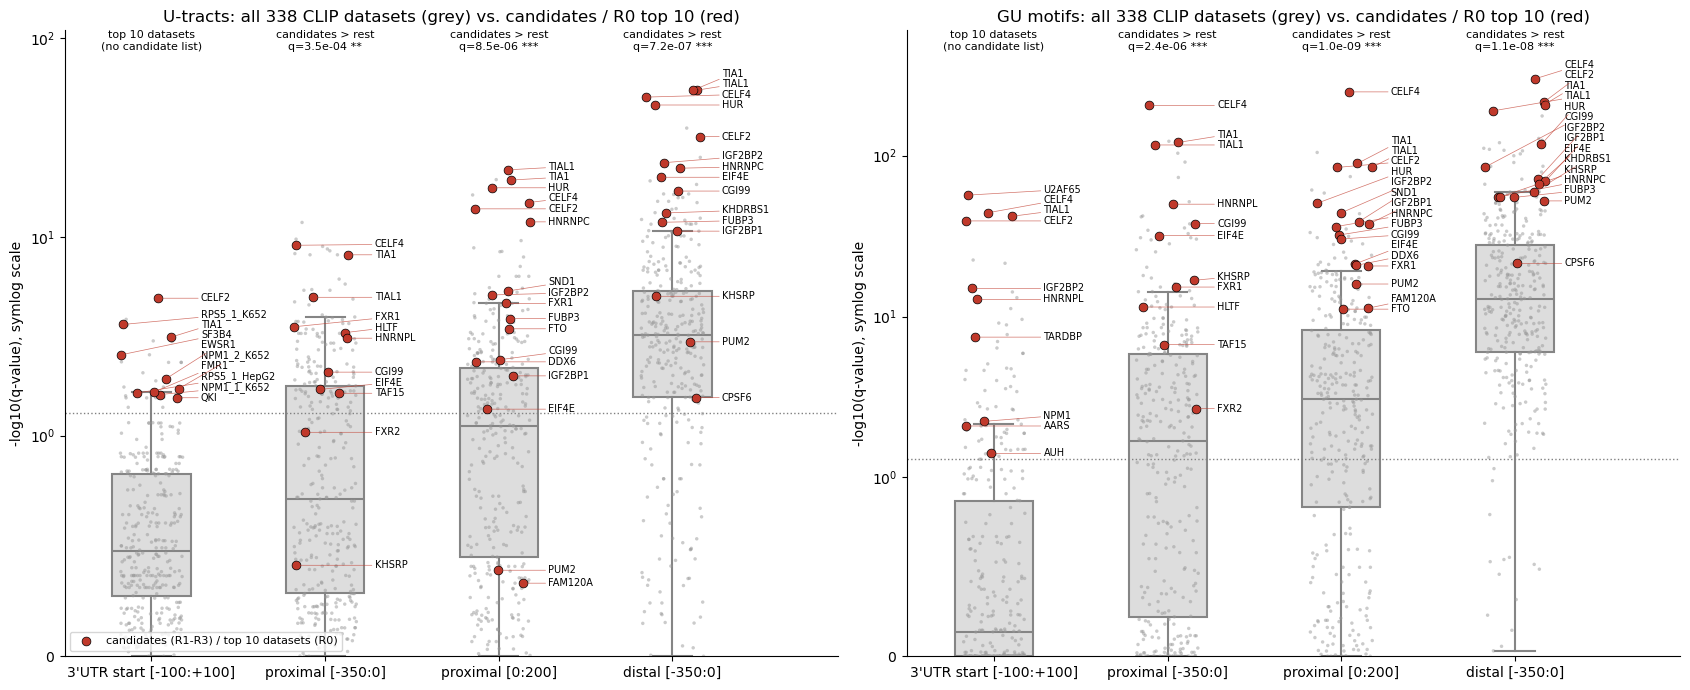

In [16]:
# -log10(q) (BH over the 338 datasets within region x element) of all datasets per region (boxplot + points), candidates in red within the distribution,
# with a leader line to their name in a column right of the box.
# y on a symlog scale (linear below 1, log above): p-values span 1 to 1e-300.
# Note: the binomial p depends on how many crosslinks a dataset has in the window (sequencing depth,
# expression), not only on the preference; the fold change above is the depth-independent measure.
cand_vs_rest = pd.read_csv(f"{ALL}/candidates_vs_rest.csv")  # reload: now also has the -log10(p) test
BOX_W, JITTER = 0.45, 0.18
rng = np.random.default_rng(0)  # fixed jitter so the figure is reproducible


def spread_labels(ax, ys, labels, min_gap_px=9):
    """Spread label heights in display space (works on any y scale); yields (y, y_label, label)."""
    to_disp, to_data = ax.transData, ax.transData.inverted()
    pts = sorted(zip([to_disp.transform((0, y))[1] for y in ys], ys, labels))
    placed = []
    for yd, y, lab in pts:
        yd_lab = max(yd, placed[-1] + min_gap_px) if placed else yd
        placed.append(yd_lab)
        yield y, to_data.transform((0, yd_lab))[1], lab


fig, axes = plt.subplots(1, len(elements), figsize=(8.5 * len(elements), 7))
for ax, element in zip(axes, elements):
    d = clip_all[clip_all["element"] == element].copy()
    d["neg_log10_p"] = -np.log10(d["q_value_bh"].clip(lower=P_FLOOR))   # y = -log10(q)
    rest = d[~d["highlight"]]
    sns.boxplot(data=rest, x="region", y="neg_log10_p", order=clip_all_region_order, color="#dddddd",
                showfliers=False, width=BOX_W, ax=ax)
    sns.stripplot(data=rest, x="region", y="neg_log10_p", order=clip_all_region_order, color="#999999",
                  size=2.5, alpha=0.5, jitter=JITTER, ax=ax)
    ax.set_yscale("symlog", linthresh=1)
    ax.set_ylim(0, d["neg_log10_p"].max() * 2)
    ax.set_xlim(-0.5, len(clip_all_region_order) - 0.05)
    fig.canvas.draw()  # fix the transform before placing labels
    for xi, region in enumerate(clip_all_region_order):
        cand = d[d["highlight"] & (d["region"] == region)]
        xs = xi + rng.uniform(-JITTER, JITTER, len(cand))   # inside the distribution
        ax.scatter(xs, cand["neg_log10_p"], s=40, color="#c0392b", edgecolor="black",
                   linewidth=0.5, zorder=4, label="candidates (R1-R3) / top 10 datasets (R0)" if xi == 0 else None)
        x_of = dict(zip(cand["label"], xs))
        x_lab = xi + BOX_W / 2 + 0.06                       # name column just right of the box
        for y, y_lab, lab in spread_labels(ax, cand["neg_log10_p"].values, cand["label"].values):
            ax.annotate(lab, (x_of[lab], y), xytext=(x_lab, y_lab), textcoords="data", fontsize=7,
                        va="center", zorder=5,
                        arrowprops=dict(arrowstyle="-", color="#c0392b", lw=0.5, alpha=0.7, shrinkA=0, shrinkB=2))
        if has_candidates(region):
            r = cand_vs_rest[(cand_vs_rest["region"] == region) & (cand_vs_rest["element"] == element)].iloc[0]
            ax.text(xi, ax.get_ylim()[1], f"candidates > rest\nq={r['q_value_bh_neglog10p']:.1e} {stars(r['q_value_bh_neglog10p'])}",
                    ha="center", va="top", fontsize=8)
        else:
            ax.text(xi, ax.get_ylim()[1], f"top {TOP_N} datasets\n(no candidate list)", ha="center", va="top", fontsize=8)
    ax.axhline(-np.log10(0.05), color="grey", linestyle=":", linewidth=1)
    ax.set_xlabel("")
    ax.set_ylabel("-log10(q-value), symlog scale")
    ax.set_title(f"{element}: all {d['dataset'].nunique()} CLIP datasets (grey) vs. candidates / R0 top {TOP_N} (red)")
    sns.despine(ax=ax)
axes[0].legend(fontsize=8, loc="lower left")
plt.tight_layout()
save_figure(f"{figures_subfolder}/boxplot_CLIP_preference_significance_all_datasets_vs_candidates.pdf",
            legend="-log10(q) (one-sided binomial test of the preference for m6A-switch-linked elements, BH within "
                   "region x element; symlog scale) of all 338 CLIP datasets (grey boxplots and points) per region, with "
                   "each region's regulators of lengthening (R1-R3) or, for R0 (3'UTR start; no candidate list), its top 10 datasets "
                   "(q < 0.05, highest fold change) in red and named, U-tracts (left) and GU motifs (right). "
                   "Text: one-sided Mann-Whitney q, candidates > rest (R1-R3). The binomial p depends on crosslink depth; the "
                   "fold change is the depth-independent measure.")
plt.show()

### 3c. Top 10 RBPs per region: significant (q < 0.05) with the highest fold change

All 338 CLIP datasets (section 3b test: one-sided binomial on crosslinked positions, BH over the 338 datasets within
region x element). Per region and element type, the 10 RBPs with the highest fold change (observed / expected share of
crosslinked positions in switch-linked elements) among their significant datasets: when an RBP has several
significant datasets (replicates / cell lines), only its highest-fold-change one is shown.
Red = one of the region's regulators of lengthening (R1-R3; R0 has no candidate list); grey = any other dataset.

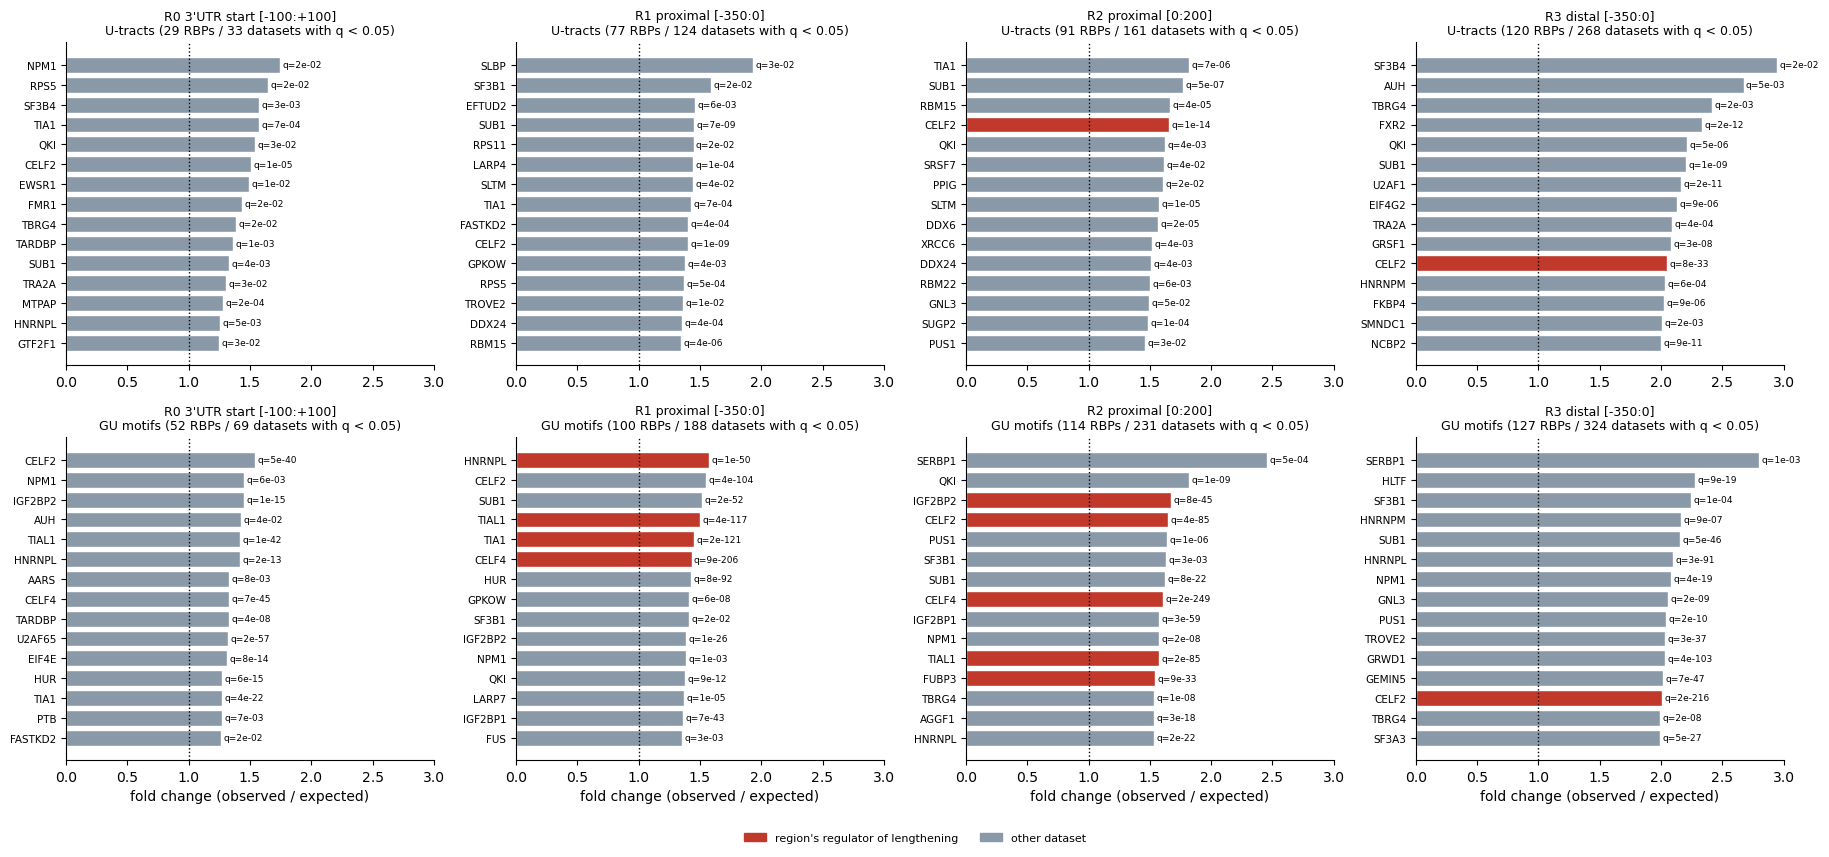

dataset     RBP  \
region                  element   rank                                   
3'UTR start [-100:+100] U-tracts  1                NPM1_1_K652    NPM1   
                                  2               RPS5_1_HepG2    RPS5   
                                  3               SF3B4_1_K652   SF3B4   
                                  4                TIA1_2_K652    TIA1   
                                  5                 QKI_1_K652     QKI   
...                                                        ...     ...   
distal [-350:0]         GU motifs 11             GRWD1_2_HepG2   GRWD1   
                                  12             GEMIN5_1_K652  GEMIN5   
                                  13    all-Celf2-293Flp_iCLIP   CELF2   
                                  14             TBRG4_2_HepG2   TBRG4   
                                  15             SF3A3_1_HepG2   SF3A3   

                                              assay  n_crosslinks_in_elements  \
region                  element   rank                                          
3'UTR start [-100:+100] U-tracts  1      eCLIP K652                       289   
                                  2     eCLIP HepG2                       382   
                                  3      eCLIP K652                       758   
                                  4      eCLIP K652                       948   
                                  5      eCLIP K652                       479   
...                                             ...                       ...   
distal [-350:0]         GU motifs 11    eCLIP HepG2                     11379   
                                  12     eCLIP K652                      5217   
                                  13          iCLIP                     25185   
                                  14    eCLIP HepG2                       821   
                                  15    eCLIP HepG2                      3044   

                                        n_in_switch_elements  fold_change  \
region                  element   rank                                      
3'UTR start [-100:+100] U-tracts  1                       32     1.741548   
                                  2                       40     1.646948   
                                  3                       76     1.576986   
                                  4                       95     1.576154   
                                  5                       47     1.543283   
...                                                      ...          ...   
distal [-350:0]         GU motifs 11                    1101     2.029229   
                                  12                     501     2.014024   
                                  13                    2406     2.003556   
                                  14                      78     1.992504   
                                  15                     289     1.991136   

                                           q_value_bh  is_candidate  
region                  element   rank                               
3'UTR start [-100:+100] U-tracts  1      2.449984e-02         False  
                                  2      2.294171e-02         False  
                                  3      2.795674e-03         False  
                                  4      7.355596e-04         False  
                                  5      2.807140e-02         False  
...                                               ...           ...  
distal [-350:0]         GU motifs 11    3.548097e-103         False  
                                  12     6.549796e-47         False  
                                  13    2.053949e-216          True  
                                  14     1.612998e-08         False  
                                  15     4.658447e-27         False  

[120 rows x 8 columns]

In [17]:
TOP_N = 15
fig, axes = plt.subplots(len(elements), len(clip_all_region_order), figsize=(4.6 * len(clip_all_region_order), 8.5))
top10_tables = []
for col, region in enumerate(clip_all_region_order):
    for row, element in enumerate(elements):
        ax = axes[row, col]
        d = clip_all[(clip_all["region"] == region) & (clip_all["element"] == element) & (clip_all["q_value_bh"] < 0.05)]
        # one dataset per RBP: its significant dataset with the highest fold change; then the top TOP_N RBPs
        t = d.sort_values("fold_change", ascending=False).drop_duplicates("RBP").head(TOP_N).copy()
        t["name"] = t["RBP"]
        top10_tables.append(t.assign(rank=range(1, len(t) + 1)))
        t = t.iloc[::-1]   # largest on top
        colors = np.where(t["is_candidate"], "#c0392b", "#8a99a8")
        ax.barh(t["name"], t["fold_change"], color=colors, edgecolor="white")
        for k, r in enumerate(t.itertuples()):
            ax.text(r.fold_change + 0.02, k, f"q={r.q_value_bh:.0e}", va="center", fontsize=6.5)
        ax.axvline(1, color="black", linestyle=":", linewidth=1)
        ax.set_xlim(0, t["fold_change"].max() * 1.3)
        ax.tick_params(axis="y", labelsize=7.5)
        ax.set_xlabel("fold change (observed / expected)" if row == len(elements) - 1 else "")
        ax.set_title(f"{r_label(region)} {region}\n{element} ({d['RBP'].nunique()} RBPs / {len(d)} datasets with q < 0.05)", fontsize=9)
        sns.despine(ax=ax)
        ax.set_xlim(0,3)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in ("#c0392b", "#8a99a8")]
fig.legend(handles, ["region's regulator of lengthening", "other dataset"], loc="lower center", ncol=2,
           fontsize=8, frameon=False, bbox_to_anchor=(0.5, -0.01))
plt.tight_layout(rect=(0, 0.03, 1, 1))
save_figure(f"{figures_subfolder}/barplot_top10_RBPs_fold_change_per_region.pdf",
            legend="Per region (columns: R0 = [-100, +100] around the 3'UTR start / stop codon, R1 = [-350, 0] upstream "
                   "of the pPAS, R2 = [0, +200] downstream of the pPAS, R3 = [-350, 0] upstream of the dPAS) and element "
                   "type (rows: U-tracts, GU motifs): the 10 RBPs with the highest fold change among the CLIP datasets "
                   "(338 datasets, 127 RBPs) with a significant preference for m6A-switch-linked elements (one-sided binomial test on "
                   "crosslinked positions, BH q < 0.05 over the 338 datasets within region x element; q printed next to "
                   "each bar). Fold change = observed / expected share of the dataset's crosslinked positions falling in "
                   "switch-linked elements (dotted line = 1). When an RBP has several significant datasets (replicates / "
                   "cell lines), only its highest-fold-change dataset is shown, so each panel has 10 different RBPs. Red = one of the region's regulators of lengthening "
                   "(R1-R3); grey = other datasets.")
plt.show()

top10 = pd.concat(top10_tables)[["region", "element", "rank", "dataset", "RBP", "assay", "n_crosslinks_in_elements",
                                 "n_in_switch_elements", "fold_change", "q_value_bh", "is_candidate"]]
top10.set_index(["region", "element", "rank"])

### 3d. Do each region's regulators of lengthening prefer m6A switches more than the background?

R1-R3 (R0 has no candidate list). Per region, fold change (observed / expected share of crosslinked positions in
switch-linked elements; section 3b test) of the region's regulators of lengthening (R1 `#51be93`, R2 `#d41c5c`, R3 `#fbb040`) vs. all other CLIP
datasets (grey; includes other replicates / cell lines of the candidate RBPs), for U-tracts and GU motifs.
q = one-sided Mann-Whitney test, regulators > background, BH over the 6 region x element tests
(`candidates_vs_rest.csv`).

The second figure splits the R2 regulators into APA and nuclear-retention regulators (`category` in `../Tables/Figure_regulators_lengthening/regulators_of_nuclear_3UTR_lengthening_D22_to_D35_CTRL_region2_downstream_pPAS_APA_vs_nuclear_retention_class.csv`, from `Figure_regulators_lengthening.ipynb`) against the same R2 background. Its test is computed here (not in the scripts): one-sided Mann-Whitney, class > background, BH over the 4 class x element tests.

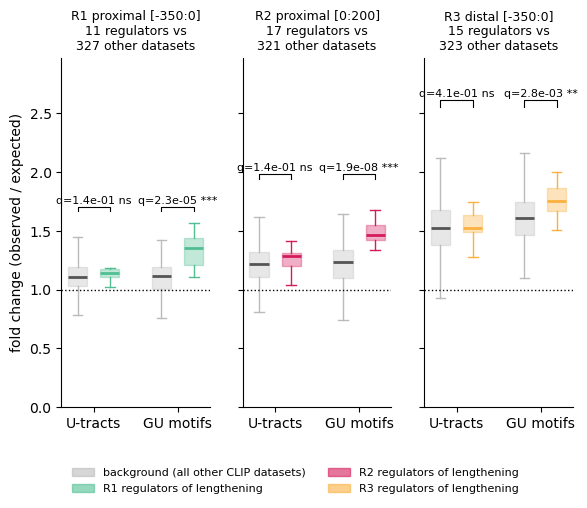

,region,element,n_candidates,n_rest,median_fc_candidates,median_fc_rest,median_percentile_candidates,p_value,q_value_bh
0,distal [-350:0],GU motifs,15,323,1.758932,1.610471,75.739645,1.397156e-03,2.794312e-03
1,distal [-350:0],U-tracts,15,323,1.526615,1.521510,50.591716,4.080915e-01,4.080915e-01
2,proximal [-350:0],GU motifs,11,327,1.354834,1.114040,94.970414,7.592652e-06,2.277796e-05
3,proximal [-350:0],U-tracts,11,327,1.141992,1.106388,60.650888,1.178501e-01,1.414201e-01
4,proximal [0:200],GU motifs,17,321,1.467307,1.239034,90.828402,3.229642e-09,1.937785e-08
5,proximal [0:200],U-tracts,17,321,1.287157,1.215749,65.680473,1.151483e-01,1.414201e-01


In [18]:
BG_COLOR = "#bbbbbb"
REG_COLORS = {"R1": "#51be93", "R2": "#d41c5c", "R3": "#fbb040"}   # regulators, per region
reg_regions = [r for r in clip_all_region_order if has_candidates(r)]   # R1-R3
fig, axes = plt.subplots(1, len(reg_regions), figsize=(2 * len(reg_regions), 4.8), sharey=True)
for ax, region in zip(axes, reg_regions):
    d = clip_all[(clip_all["region"] == region) & clip_all["fold_change"].notna()].copy()
    d["group"] = np.where(d["is_candidate"], "regulators", "background")
    order_x = [(e, g) for e in elements for g in ("background", "regulators")]
    pos = {k: i + (i // 2) * 0.6 for i, k in enumerate(order_x)}   # gap between element types
    for (e, g), x in pos.items():
        v = d[(d["element"] == e) & (d["group"] == g)]["fold_change"]
        color = REG_COLORS[r_label(region)] if g == "regulators" else BG_COLOR
        ax.boxplot(v, positions=[x], widths=0.6, showfliers=False, patch_artist=True,
                   boxprops=dict(facecolor=color, alpha=0.35, edgecolor=color),
                   medianprops=dict(color=color if g == "regulators" else "#555555", lw=2),
                   whiskerprops=dict(color=color), capprops=dict(color=color))
    ymax = d["fold_change"].quantile(0.995) * 1.15
    for e in elements:
        r = cand_vs_rest[(cand_vs_rest["region"] == region) & (cand_vs_rest["element"] == e)].iloc[0]
        x0, x1 = pos[(e, "background")], pos[(e, "regulators")]
        ax.plot([x0, x0, x1, x1], [ymax * 0.93, ymax * 0.95, ymax * 0.95, ymax * 0.93], color="black", lw=0.8)
        ax.text((x0 + x1) / 2, ymax * 0.955, f"q={r['q_value_bh']:.1e} {stars(r['q_value_bh'])}",
                ha="center", va="bottom", fontsize=8)
    ax.axhline(1, color="black", linestyle=":", linewidth=1)
    ax.set_xticks([(pos[(e, "background")] + pos[(e, "regulators")]) / 2 for e in elements])
    ax.set_xticklabels(elements)
    ax.set_ylim(0, ymax * 1.08)
    n_reg = d[d["is_candidate"]]["dataset"].nunique()
    ax.set_title(f"{r_label(region)} {region}\n{n_reg} regulators vs\n{d['dataset'].nunique() - n_reg} other datasets",
                 fontsize=9)
    ax.set_ylabel("fold change (observed / expected)" if ax is axes[0] else "")
    sns.despine(ax=ax)
handles = [plt.Rectangle((0, 0), 1, 1, color=c, alpha=0.6) for c in [BG_COLOR] + list(REG_COLORS.values())]
fig.legend(handles, ["background (all other CLIP datasets)"] + [f"{r} regulators of lengthening" for r in REG_COLORS],
           loc="lower center", ncol=2, fontsize=8, frameon=False, bbox_to_anchor=(0.5, -0.06))
plt.tight_layout(rect=(0, 0.06, 1, 1))
save_figure(f"{figures_subfolder}/boxplot_regulators_vs_background_fold_change_R1_R3.pdf",
            legend="For each region with a list of regulators of lengthening (R1 = [-350, 0] upstream of the pPAS, R2 = "
                   "[0, +200] downstream of the pPAS, R3 = [-350, 0] upstream of the dPAS), fold change of the CLIP "
                   "crosslinks' preference for m6A-switch-linked elements (observed / expected share of crosslinked "
                   "positions in switch-linked elements; dotted line = 1, no preference) of the region's regulators "
                   "(R1 green, R2 red, R3 orange) vs all other of the 338 CLIP datasets (grey; including other replicates / cell lines of the "
                   "candidate RBPs), for U-tracts and GU motifs. Boxes = median and IQR, whiskers 1.5 x IQR (one value per dataset). q = one-sided "
                   "Mann-Whitney test, regulators > background, BH over the 6 region x element tests.")
plt.show()
cand_vs_rest[cand_vs_rest["n_candidates"] > 0][["region", "element", "n_candidates", "n_rest", "median_fc_candidates",
                                               "median_fc_rest", "median_percentile_candidates", "p_value", "q_value_bh"]]

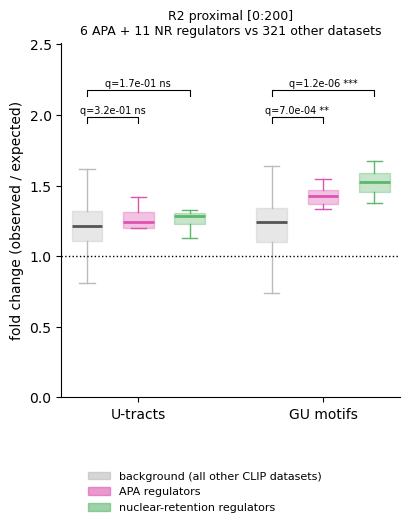

,element,class,n_class,n_background,median_fc_class,median_fc_background,p_value,q_value_bh
0,U-tracts,APA,6,321,1.243609,1.215749,3.165945e-01,0.316594
1,U-tracts,Nuclear retention,11,321,1.287587,1.215749,1.244020e-01,0.165869
2,GU motifs,APA,6,321,1.429006,1.239034,3.502538e-04,0.000701
3,GU motifs,Nuclear retention,11,321,1.525224,1.239034,2.969410e-07,0.000001


In [19]:
# R2 only: regulators split into APA and nuclear-retention (category from Figure_regulators_lengthening.ipynb)
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

CAT_COLORS = {"APA": "#dd54af", "Nuclear retention": "#5cb76b"}
region = "proximal [0:200]"   # R2
cat_r2 = pd.read_csv(figures.lengthening_regulators_csv(2), index_col=0)
# CLIP names differ by a "-" before "_" between the two pipelines (all-HuR-FlpIn293-_iCLIP vs all-HuR-FlpIn293_iCLIP)
cat_of = dict(zip(cat_r2["regulator"].str.replace("-_", "_", regex=False), cat_r2["category"]))

d = clip_all[(clip_all["region"] == region) & clip_all["fold_change"].notna()].copy()
d["group"] = np.where(d["is_candidate"], d["dataset"].map(cat_of), "background")
assert d.loc[d["is_candidate"], "group"].notna().all(), "R2 regulator without APA / NR class"
groups = ["background", "APA", "Nuclear retention"]

# one-sided Mann-Whitney, class > background, BH over the 2 classes x 2 elements
tests = []
for e in elements:
    bg = d[(d["element"] == e) & (d["group"] == "background")]["fold_change"]
    for g in groups[1:]:
        v = d[(d["element"] == e) & (d["group"] == g)]["fold_change"]
        tests.append({"element": e, "class": g, "n_class": len(v), "n_background": len(bg),
                      "median_fc_class": v.median(), "median_fc_background": bg.median(),
                      "p_value": mannwhitneyu(v, bg, alternative="greater").pvalue})
tests = pd.DataFrame(tests)
tests["q_value_bh"] = multipletests(tests["p_value"], method="fdr_bh")[1]

fig, ax = plt.subplots(figsize=(4.2, 4.8))
order_x = [(e, g) for e in elements for g in groups]
pos = {k: i + (i // 3) * 0.6 for i, k in enumerate(order_x)}   # gap between element types
for (e, g), x in pos.items():
    v = d[(d["element"] == e) & (d["group"] == g)]["fold_change"]
    color = CAT_COLORS.get(g, BG_COLOR)
    ax.boxplot(v, positions=[x], widths=0.6, showfliers=False, patch_artist=True,
               boxprops=dict(facecolor=color, alpha=0.35, edgecolor=color),
               medianprops=dict(color=color if g != "background" else "#555555", lw=2),
               whiskerprops=dict(color=color), capprops=dict(color=color))
ymax = d["fold_change"].quantile(0.995) * 1.15
for e in elements:
    for k, g in enumerate(groups[1:]):
        q = tests[(tests["element"] == e) & (tests["class"] == g)]["q_value_bh"].iloc[0]
        x0, x1 = pos[(e, "background")], pos[(e, g)]
        y = ymax * (0.93 + 0.09 * k)
        ax.plot([x0, x0, x1, x1], [y, y + ymax * 0.02, y + ymax * 0.02, y], color="black", lw=0.8)
        ax.text((x0 + x1) / 2, y + ymax * 0.025, f"q={q:.1e} {stars(q)}", ha="center", va="bottom", fontsize=7)
ax.axhline(1, color="black", linestyle=":", linewidth=1)
ax.set_xticks([pos[(e, "APA")] for e in elements])
ax.set_xticklabels(elements)
ax.set_ylim(0, ymax * 1.2)
n = d.drop_duplicates("dataset")["group"].value_counts()
ax.set_title(f"R2 {region}\n{n['APA']} APA + {n['Nuclear retention']} NR regulators vs {n['background']} other datasets",
             fontsize=9)
ax.set_ylabel("fold change (observed / expected)")
sns.despine(ax=ax)
handles = [plt.Rectangle((0, 0), 1, 1, color=c, alpha=0.6) for c in (BG_COLOR, CAT_COLORS["APA"], CAT_COLORS["Nuclear retention"])]
fig.legend(handles, ["background (all other CLIP datasets)", "APA regulators", "nuclear-retention regulators"],
           loc="lower center", ncol=1, fontsize=8, frameon=False, bbox_to_anchor=(0.5, -0.1))
plt.tight_layout(rect=(0, 0.08, 1, 1))
save_figure(f"{figures_subfolder}/boxplot_regulators_vs_background_fold_change_R2_APA_vs_NR.pdf",
            legend="R2 ([0, +200] downstream of the pPAS): fold change of the CLIP crosslinks' preference for "
                   "m6A-switch-linked elements (observed / expected share of crosslinked positions in switch-linked "
                   "elements; dotted line = 1, no preference) of the R2 regulators of lengthening, split into APA (pink; "
                   "significant R2 Welch score in both the nuclear and cytoplasmic fractions of CTRL at D35) and "
                   "nuclear-retention regulators (green; nucleus only), vs all other of the 338 CLIP datasets (grey; "
                   "including other replicates / cell lines of the candidate RBPs), for U-tracts and GU motifs. Boxes = "
                   "median and IQR, whiskers 1.5 x IQR (one value per dataset). q = one-sided Mann-Whitney test, class > "
                   "background, BH over the 4 class x element tests.")
plt.show()
tests

In [20]:
clip_all[clip_all['region'] == 'proximal [-350:0]'].sort_values(by='q_value_bh').head(100)

,dataset,RBP,assay,region,element,n_crosslinks_in_elements,n_in_switch_elements,observed_rate,expected_rate,odds_ratio,p_value,fold_change,log2_odds_ratio,is_candidate,q_value_bh,rank_fc,percentile_fc,highlight,label
1357,all-Celf4-FlpIn293_iCLIP,CELF4,iCLIP,proximal [-350:0],GU motifs,61300,7460,0.121697,0.084989,1.491746,2.620195e-208,1.431902,0.577001,True,8.856259e-206,6.0,98.520710,True,CELF4
1373,all-U2AF65-Hela-wt1_iCLIP,U2AF65,iCLIP,proximal [-350:0],GU motifs,61331,6933,0.113042,0.084989,1.372143,1.189249e-125,1.330075,0.456430,False,2.009830e-123,22.0,93.786982,False,U2AF65
1356,all-TIA1-Hela_iCLIP,TIA1,iCLIP,proximal [-350:0],GU motifs,32816,4055,0.123568,0.084989,1.517916,1.759807e-123,1.453919,0.602092,True,1.982716e-121,5.0,98.816568,True,TIA1
1355,all-TIAL1-Hela_iCLIP,TIAL1,iCLIP,proximal [-350:0],GU motifs,26581,3383,0.127271,0.084989,1.570046,4.892944e-119,1.497496,0.650807,True,4.134537e-117,4.0,99.112426,True,TIAL1
1353,all-Celf2-293Flp_iCLIP,CELF2,iCLIP,proximal [-350:0],GU motifs,19809,2603,0.131405,0.084989,1.628753,5.413455e-106,1.546132,0.703768,False,3.659496e-104,2.0,99.704142,False,CELF2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1445,AGGF1_1_K652,AGGF1,eCLIP K652,proximal [-350:0],GU motifs,8634,873,0.101112,0.084989,1.211037,9.131913e-08,1.189699,0.276243,False,3.589054e-07,94.0,72.485207,False,AGGF1
1427,TARDBP_1_K652,TARDBP,eCLIP K652,proximal [-350:0],GU motifs,7166,736,0.102707,0.084989,1.232332,9.538344e-08,1.208470,0.301391,False,3.705701e-07,76.0,77.810651,False,TARDBP
1446,DROSHA_2_K652,DROSHA,eCLIP K652,proximal [-350:0],GU motifs,8437,853,0.101102,0.084989,1.210909,1.281501e-07,1.189586,0.276091,False,4.922128e-07,95.0,72.189349,False,DROSHA
1438,HNRNPC_1_HepG2,HNRNPC,eCLIP HepG2,proximal [-350:0],GU motifs,7655,780,0.101894,0.084989,1.221470,1.354642e-07,1.198904,0.288619,False,5.144597e-07,87.0,74.556213,False,HNRNPC
